# Finite Difference Methods for Barrier Options

This notebook studies the numerical solution of the heat equation with absorbing boundaries, which is the model problem behind the pricing of double barrier knock-out options. It compares the explicit, implicit and Crank-Nicolson schemes (stability, accuracy, cost), checks the results against a Monte Carlo estimator, and finally prices a double barrier call under Black-Scholes.

It started as a lab assignment in numerical methods for PDEs at Ensimag (Grenoble INP), and was then extended with additional experiments.

### Problem

Find $u(x,t)$ on $[a,b]\times[0,T]$ such that
$$u_t = \frac{\sigma^2}{2}\,u_{xx},\qquad u(x,0)=\varphi(x),\qquad u(a,t)=\alpha,\quad u(b,t)=\beta,$$
with $a=-1$, $b=1$, $T=1$, $\sigma^2=0.1$, $\alpha=\beta=0$ and $\varphi(x)=\max(x,0)$.

### Why this is a pricing problem

After the change of variables $x=\ln s$, $\tau=T-t$, then $V=e^{cx+d\tau}w$, the Black-Scholes equation becomes the heat equation. The barriers $s=L$ and $s=U$ become zero Dirichlet conditions. All schemes can therefore be studied on the heat equation, and the results carry over directly to option prices (Section 8).

### Contents
1. Matrix form: a single solver, the θ-scheme, covering all three schemes
2. A first look at the solution: what the heat equation does
3. Stability of the explicit scheme: experiment, explanation (Von Neumann, maximum principle), stability map
4. Analysis of Crank-Nicolson: second order in time and space, unconditional stability, but spurious oscillations
5. Choice of linear solver
6. Convergence: observed orders, choosing $M$ as a function of $N$, accuracy vs cost
7. Monte Carlo: sample paths, estimator, discrete barrier bias, comparison with finite differences
8. Back to Black-Scholes: pricing a double barrier knock-out call
9. Summary of results

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg as sl

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

# Problem parameters
a, b = -1.0, 1.0
T = 1.0
sigma2 = 0.1          # sigma^2
alpha = beta = 0.0    # boundary values

def phi(x):
    return np.maximum(x, 0.0)

## 1. Matrix form: the θ-scheme

The grid has $N+2$ points $x_0=a,\dots,x_{N+1}=b$, so $\Delta x = (b-a)/(N+1)$, and $\Delta t = T/M$. Let $U^m=(u^m_1,\dots,u^m_N)^T$ be the interior unknowns at time step $m$, with $u^m_0=\alpha$ and $u^m_{N+1}=\beta$ known. The discrete Laplacian reads $\dfrac{u_{n-1}-2u_n+u_{n+1}}{\Delta x^2} \;\to\; -\dfrac{1}{\Delta x^2}(AU - B)$, where $A=\mathrm{tridiag}(-1,2,-1)$ and $B=(\alpha,0,\dots,0,\beta)^T$. Multiplying by $\Delta t$ and setting $\mu=\dfrac{\sigma^2\Delta t}{2\Delta x^2}$:

| Scheme | Matrix form |
|---|---|
| Explicit | $U^{m+1} = (I-\mu A)\,U^m + \mu B$ |
| Implicit | $(I+\mu A)\,U^{m+1} = U^m + \mu B$ |
| Crank-Nicolson | $(I+\tfrac{\mu}{2}A)\,U^{m+1} = (I-\tfrac{\mu}{2}A)\,U^m + \mu B$ |

All three are special cases of the **θ-scheme**:
$$(I+\theta\mu A)\,U^{m+1} = \big(I-(1-\theta)\mu A\big)\,U^m + \mu B$$
with $\theta=0$ (explicit), $\theta=1$ (implicit) and $\theta=\tfrac12$ (Crank-Nicolson). A **single function** therefore implements all three.

In [ ]:
EXPLICIT, IMPLICIT, CN = 0.0, 1.0, 0.5
NAMES = {EXPLICIT: "Explicit", IMPLICIT: "Implicit", CN: "Crank-Nicolson"}

def apply_A(u):
    # Computes A @ u without building A (tridiagonal 2, -1)
    r = 2 * u
    r[1:] -= u[:-1]
    r[:-1] -= u[1:]
    return r

def solve(theta, N, M, phi, a=a, b=b, T=T, sigma2=sigma2, alpha=alpha, beta=beta, history=False):
    # theta-scheme for u_t = sigma2/2 u_xx on [a,b]x[0,T]
    # returns x (N+2 points), the solution (at time T, or at every time step), and mu
    dx = (b - a) / (N + 1)
    dt = T / M
    mu = sigma2 * dt / (2 * dx**2)
    x = np.linspace(a, b, N + 2)

    B = np.zeros(N)
    B[0], B[-1] = alpha, beta

    # Matrix I + theta*mu*A in banded storage (for solve_banded)
    ab = np.zeros((3, N))
    ab[0, 1:] = -theta * mu # superdiagonal
    ab[1, :] = 1 + 2 * theta * mu  # diagonal
    ab[2, :-1] = -theta * mu # subdiagonal

    u = phi(x[1:-1]).astype(float)
    hist = [u]
    for m in range(M):
        rhs = u - (1 - theta) * mu * apply_A(u) + mu * B
        if theta == 0:
            u = rhs # explicit: no linear system
        else:
            u = sl.solve_banded((1, 1), ab, rhs) # tridiagonal system
        if history:
            hist.append(u)

    def with_boundaries(v):
        return np.concatenate([[alpha], v, [beta]])

    if history:
        return x, np.array([with_boundaries(v) for v in hist]), mu
    return x, with_boundaries(u), mu

## 2. A first look at the solution

With $N=100$ and $M=1000$, we get $\mu\approx0.13<1/2$. All three schemes are then stable and should produce the same curve.

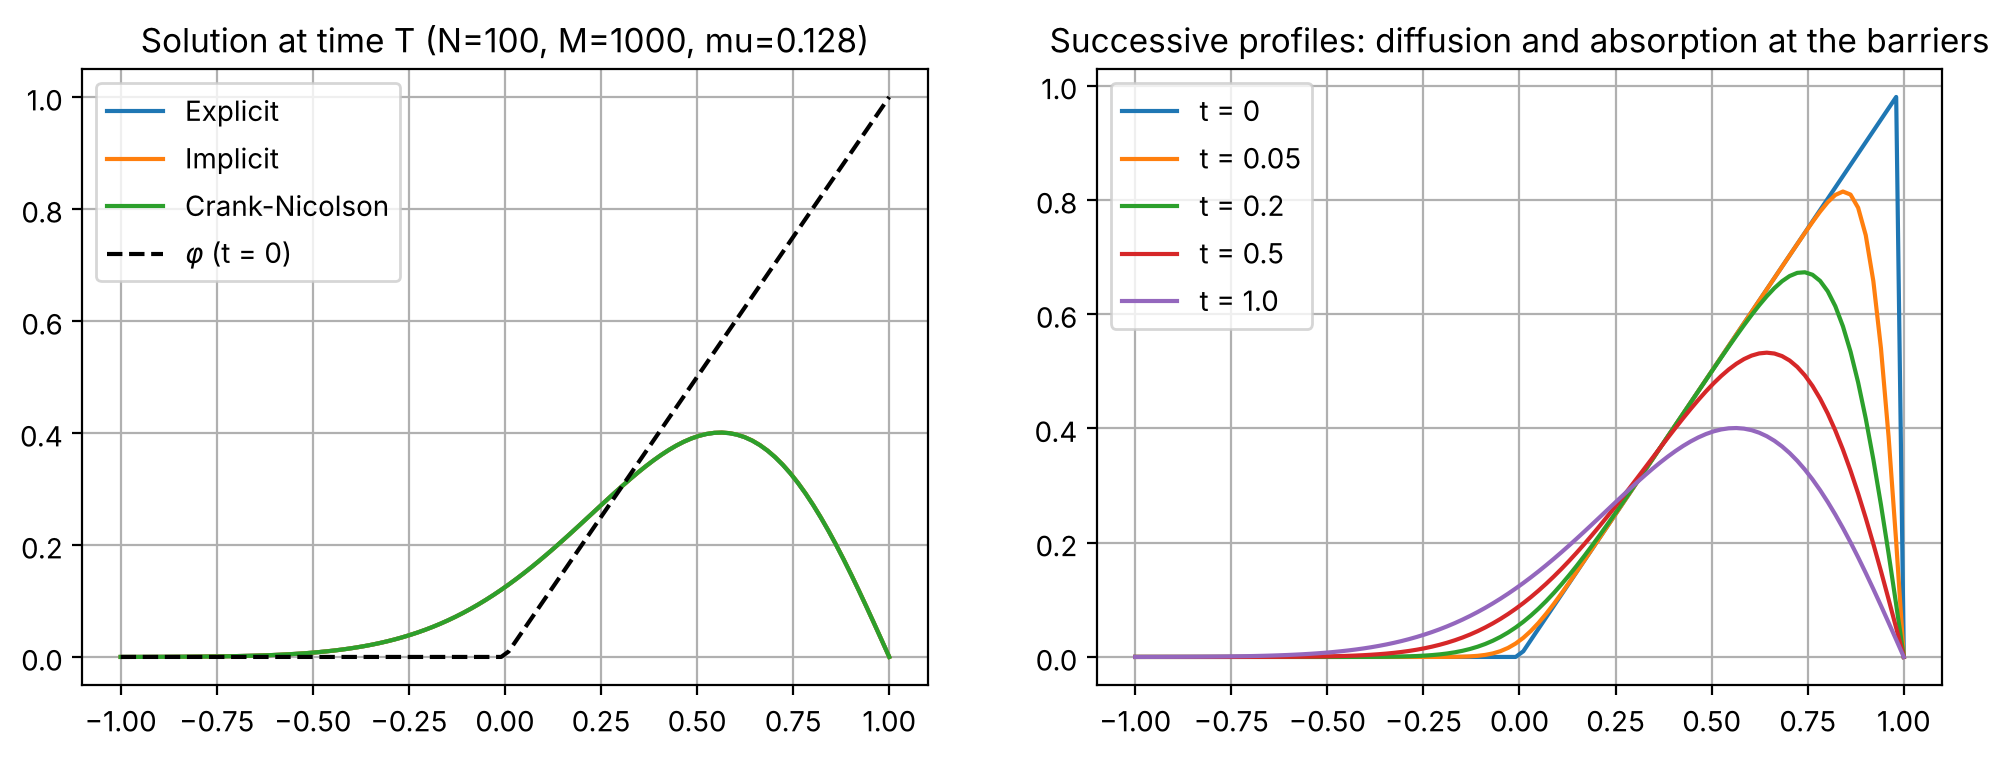

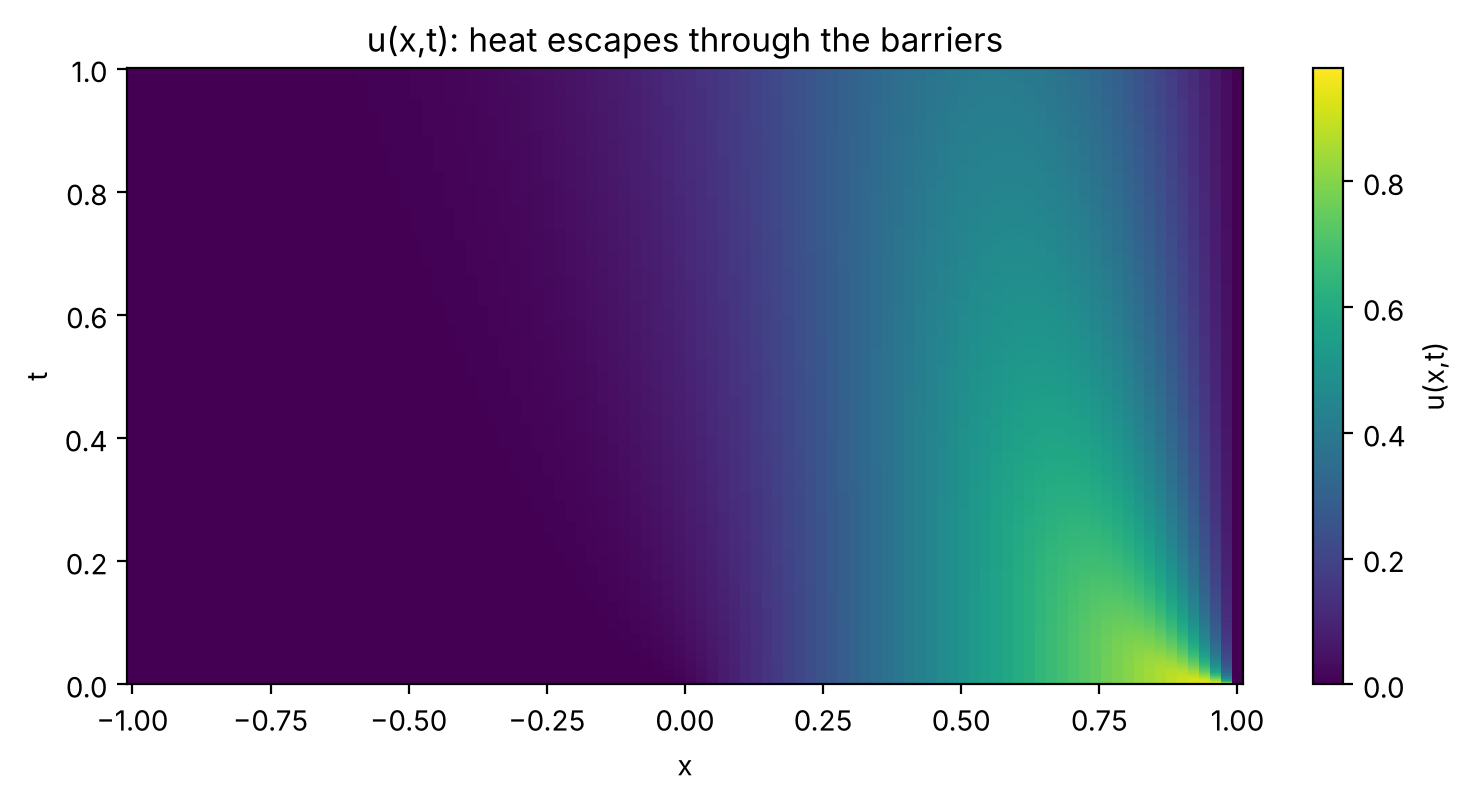

In [ ]:
N, M = 100, 1000
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for theta in [EXPLICIT, IMPLICIT, CN]:
    x, u, mu = solve(theta, N, M, phi)
    ax[0].plot(x, u, label=NAMES[theta])
ax[0].plot(x, phi(x), "k--", label=r"$\varphi$ (t = 0)")
ax[0].set_title(f"Solution at time T (N={N}, M={M}, mu={mu:.3f})")
ax[0].legend()

x, U, mu = solve(CN, N, M, phi, history=True)
for t in [0, 0.05, 0.2, 0.5, 1.0]:
    ax[1].plot(x, U[int(t * M)], label=f"t = {t}")
ax[1].set_title("Successive profiles: diffusion and absorption at the barriers")
ax[1].legend()
plt.show()

plt.figure(figsize=(9, 4))
plt.pcolormesh(x, np.linspace(0, T, M + 1), U, shading="auto", cmap="viridis")
plt.colorbar(label="u(x,t)")
plt.xlabel("x"); plt.ylabel("t")
plt.title("u(x,t): heat escapes through the barriers")
plt.grid(False)
plt.show()

**Observations and link with the option**
- The **kink** of $\varphi$ at $x=0$ is **smoothed out immediately**: diffusion regularizes the solution. This is why an option price is smooth even when the payoff has a kink.
- At $x=b$, $\varphi(b)=1$ while the boundary condition imposes $\beta=0$. The initial data is therefore **discontinuous** at the boundary. The solution drops sharply near $b$: this is the knock-out. Starting close to the barrier means a high probability of hitting it, hence a zero payoff.
- The total "mass" decreases over time as it leaks through the absorbing boundaries. In probabilistic terms, these are the paths killed by the barrier (Section 7).

## 3. Stability of the explicit scheme

### 3.1 The experiment

We fix $N=100$ and choose $M$ so as to get a few values of $\mu$ around $1/2$.

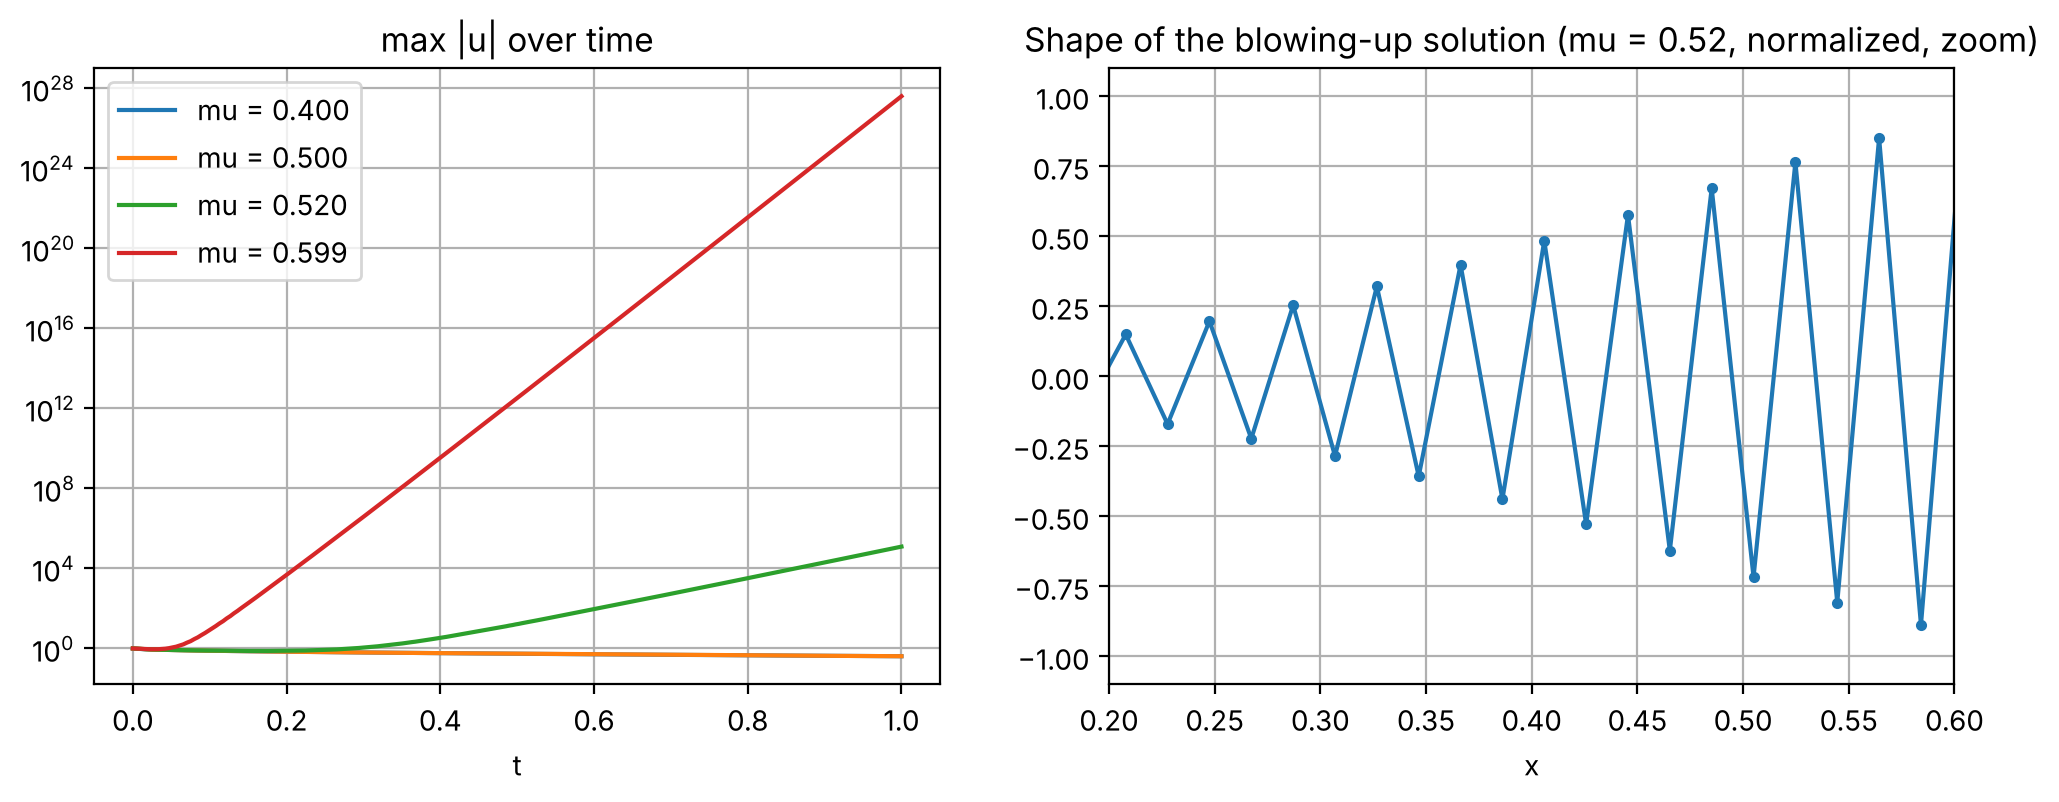

In [ ]:
N = 100
dx = (b - a) / (N + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for mu_target in [0.4, 0.5, 0.52, 0.6]:
    M = int(round(sigma2 * T / (2 * dx**2 * mu_target)))
    x, U, mu = solve(EXPLICIT, N, M, phi, history=True)
    ax[0].semilogy(np.linspace(0, T, M + 1), np.abs(U).max(axis=1), label=f"mu = {mu:.3f}")
    if mu_target == 0.52:
        zigzag = U[-1] / np.abs(U[-1]).max()  
ax[0].set_title("max |u| over time")
ax[0].set_xlabel("t"); ax[0].legend()
ax[1].plot(x, zigzag, "o-", ms=3)
ax[1].set_xlim(0.2, 0.6)
ax[1].set_title("Shape of the blowing-up solution (mu = 0.52, normalized, zoom)")
ax[1].set_xlabel("x")
plt.show()

For $\mu\le 1/2$, $\max|u|$ stays bounded by 1. For $\mu>1/2$, it **grows exponentially**, even for $\mu=0.52$, barely above the threshold. The blowing-up solution is not arbitrary: it is a **zigzag** $(-1)^n$, the highest-frequency mode the grid can represent. The next section explains why.

### 3.2 Why? Von Neumann analysis

Plug a Fourier mode $u^m_n = g^m e^{in\xi}$ into the scheme, with frequency $\xi\in[0,\pi]$. Since $u_{n-1}-2u_n+u_{n+1} = -4\sin^2(\xi/2)\,u_n$, writing $s=\sin^2(\xi/2)\in[0,1]$ gives the **amplification factor** of each scheme:

| Scheme | $g(\xi)$ | Condition $\lvert g\rvert\le1$ for all $\xi$ |
|---|---|---|
| Explicit | $1-4\mu s$ | $4\mu\le2 \iff \mu\le\tfrac12$ |
| Implicit | $\dfrac{1}{1+4\mu s}$ | always satisfied |
| Crank-Nicolson | $\dfrac{1-2\mu s}{1+2\mu s}$ | always satisfied, since $\lvert1-y\rvert\le1+y$ for $y\ge0$ |

For the explicit scheme, the worst case is $\xi=\pi$, i.e. $s=1$ and $g=1-4\mu$. This is the zigzag: as soon as $\mu>1/2$, it is multiplied by $1-4\mu<-1$ at every step. The sign alternates and the amplitude blows up.

**Link with the matrices.** With Dirichlet boundary conditions this is more than a heuristic. The eigenvectors of $A$ are exactly discrete sine modes, with eigenvalues $\lambda_k = 4\sin^2\!\big(\tfrac{k\pi}{2(N+1)}\big)$. The eigenvalues of the iteration matrix are therefore the $g(\xi_k)$, with $\xi_k = k\pi/(N+1)$. The dots in the plot below are these eigenvalues, computed numerically.

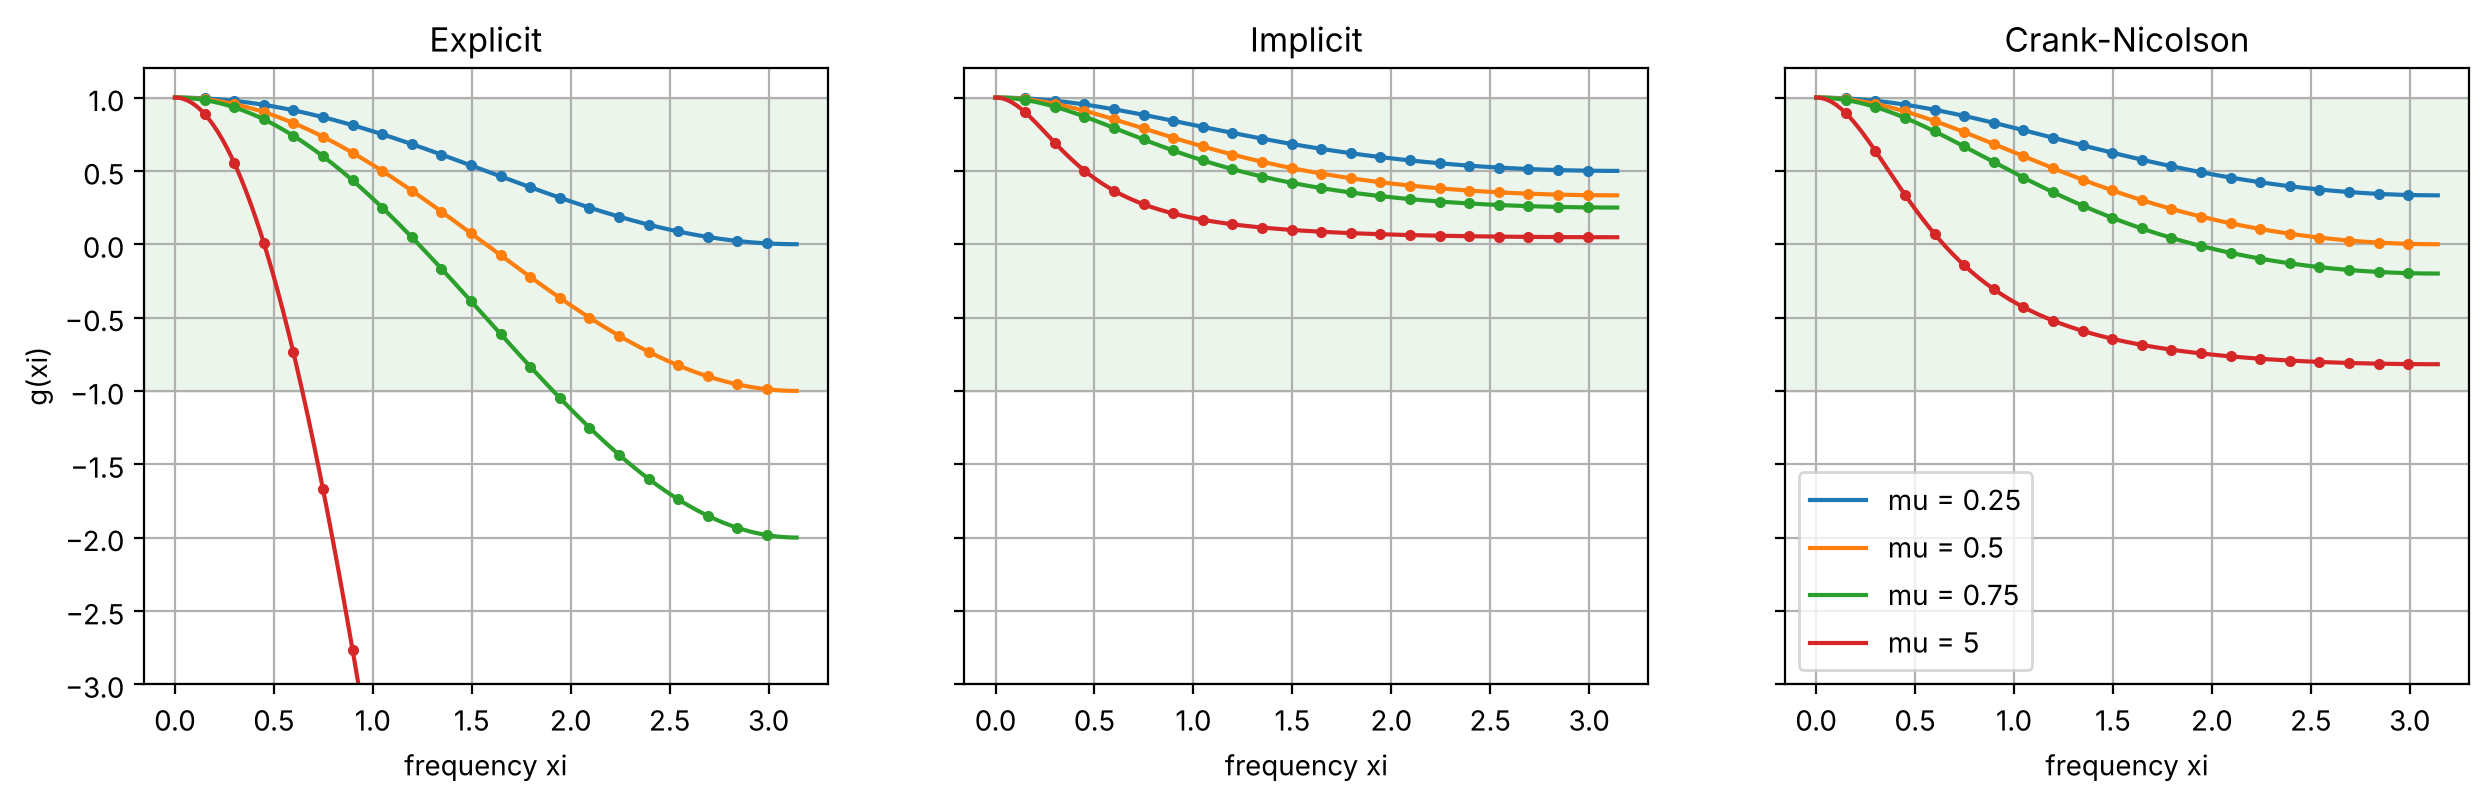

In [ ]:
xi = np.linspace(0, np.pi, 300)
s = np.sin(xi / 2)**2
N = 20
A = 2 * np.eye(N) - np.eye(N, k=1) - np.eye(N, k=-1)
xi_k = np.arange(1, N + 1) * np.pi / (N + 1)

fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for mu in [0.25, 0.5, 0.75, 5]:
    g = {EXPLICIT: 1 - 4*mu*s, IMPLICIT: 1 / (1 + 4*mu*s), CN: (1 - 2*mu*s) / (1 + 2*mu*s)}
    for i, theta in enumerate([EXPLICIT, IMPLICIT, CN]):
        line, = ax[i].plot(xi, g[theta], label=f"mu = {mu}")
        M_iter = np.linalg.solve(np.eye(N) + theta*mu*A, np.eye(N) - (1-theta)*mu*A)
        eigs = np.sort(np.linalg.eigvals(M_iter).real)[::-1]
        ax[i].plot(xi_k, eigs, "o", ms=3, color=line.get_color())
for i, theta in enumerate([EXPLICIT, IMPLICIT, CN]):
    ax[i].axhspan(-1, 1, color="green", alpha=0.08)
    ax[i].set_title(NAMES[theta]); ax[i].set_xlabel("frequency xi")
ax[0].set_ylim(-3, 1.2); ax[0].set_ylabel("g(xi)"); ax[2].legend()
plt.show()

**Reading the plot** (the green band is $|g|\le1$, the stable region)
- **Explicit**: $g$ is linear in $s$. As soon as $\mu>1/2$, the high frequencies exit the band from below.
- **Implicit**: $0<g\le1$ always. All frequencies are damped, and high frequencies are damped very strongly.
- **Crank-Nicolson**: $|g|\le1$ always, but for large $\mu$, $g(\pi)\to-1$. High frequencies are then **barely damped and flip sign at every step**. This shows up in Section 4.
- The **exact** factor (that of the continuous equation over one step $\Delta t$) is $e^{-\mu\xi^2}$. For low frequencies ($\xi\to0$), all three $g$ approach it: the schemes agree on low frequencies and only differ on high ones.

### 3.3 Another view: maximum principle and random walk

The explicit scheme can be rewritten as
$$u^{m+1}_n = \mu\,u^m_{n-1} + (1-2\mu)\,u^m_n + \mu\,u^m_{n+1}.$$
If $\mu\le1/2$, the three weights are **nonnegative and sum to 1**. $u^{m+1}_n$ is then an **average** of its neighbors, so $\min\varphi\le u\le\max\varphi$: this is the discrete maximum principle.

It is also exactly an **expectation over a trinomial random walk**: move left with probability $\mu$, stay with probability $1-2\mu$, move right with probability $\mu$. The condition $\mu\le1/2$ simply says that "the probability of staying put is nonnegative". The explicit scheme **is** a trinomial tree, which links it to the Monte Carlo approach of Section 7.

### 3.4 Stability map: the parabola

$\mu\le\frac12 \iff \Delta t \le \dfrac{\Delta x^2}{\sigma^2}$. In the $(\Delta x,\Delta t)$ plane, the stability boundary is therefore a **parabola**.

We check this by running the explicit scheme on many $(N,M)$ pairs. For each pair, we check whether the maximum principle holds, i.e. whether $|u^m_n|\le 1$ at all times (since $0\le\varphi\le1$). Each point is colored by $\max_{m,n}|u^m_n|$: green if this max equals 1, increasingly red as it grows.

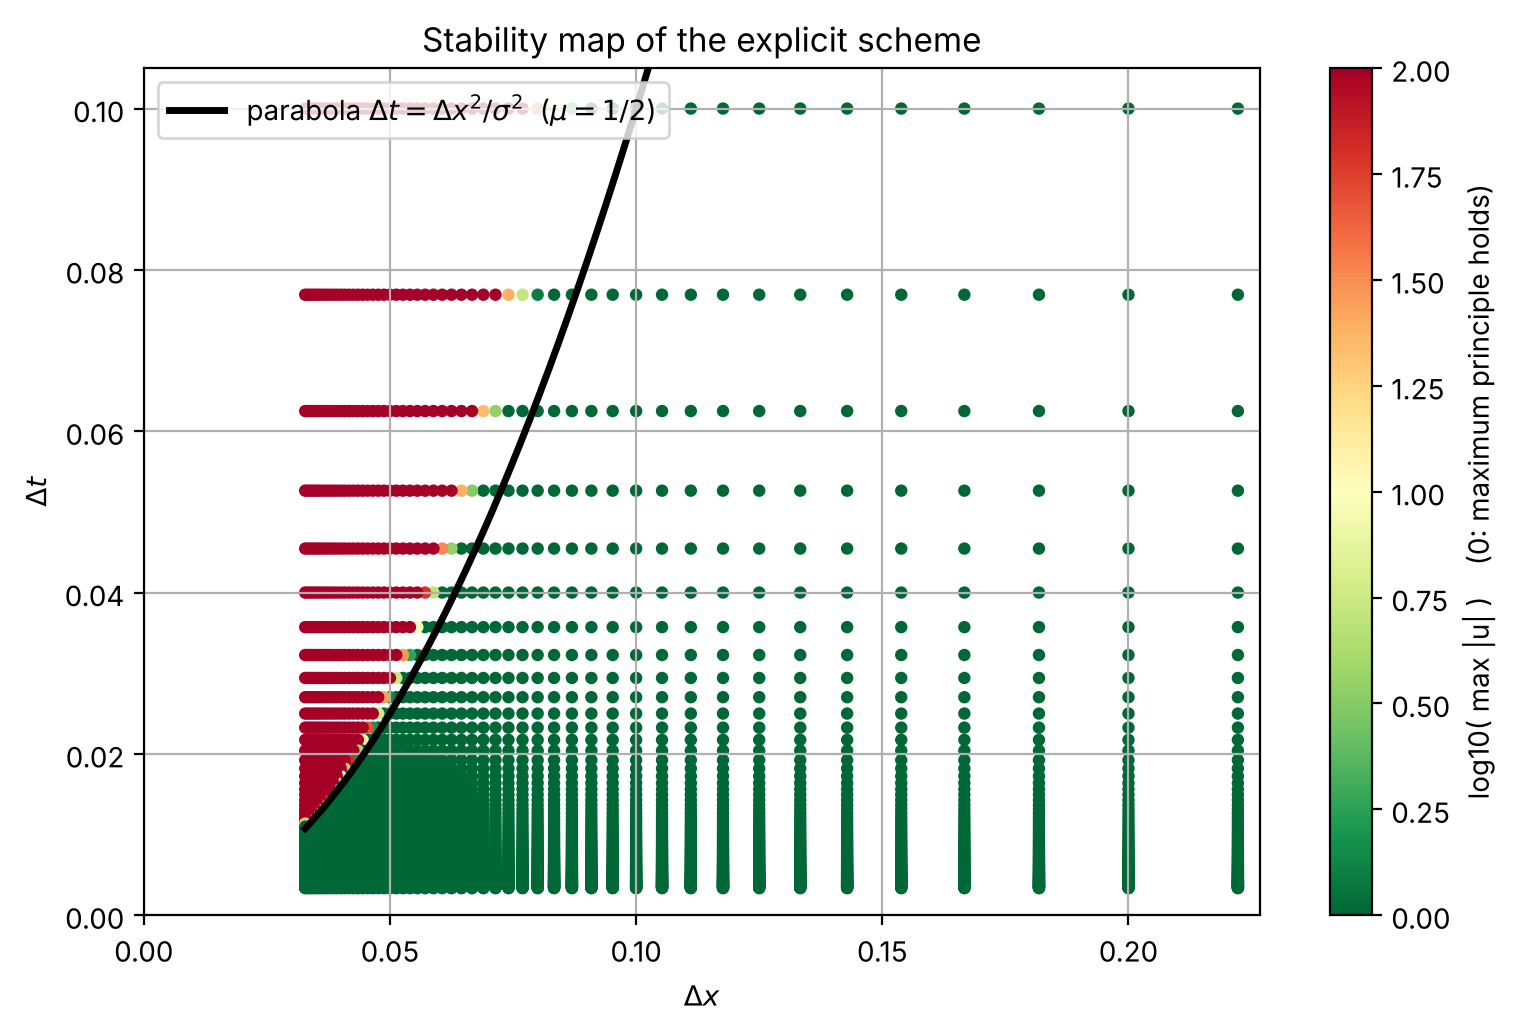

Points with mu <= 1/2: max |u| = 0.967213
Points with mu >  1/2: fraction violating the maximum principle = 0.923


In [ ]:
DX, DT, MAXU = [], [], []
for N in range(8, 61, 1):
    for M in range(10, 301, 3):
        x, U, mu = solve(EXPLICIT, N, M, phi, history=True)
        DX.append((b - a) / (N + 1))
        DT.append(T / M)
        MAXU.append(np.abs(U).max())
DX, DT, MAXU = np.array(DX), np.array(DT), np.array(MAXU)

plt.figure(figsize=(9, 5.5))
sc = plt.scatter(DX, DT, c=np.log10(MAXU), s=12, cmap="RdYlGn_r", vmin=0, vmax=2)
plt.colorbar(sc, label="log10( max |u| )    (0: maximum principle holds)")
dx_fine = np.linspace(DX.min(), DX.max(), 200)
plt.plot(dx_fine, dx_fine**2 / sigma2, "k", lw=2.5, label=r"parabola $\Delta t = \Delta x^2/\sigma^2$  ($\mu = 1/2$)")
plt.xlim(0, DX.max() * 1.02); plt.ylim(0, 0.105)
plt.xlabel(r"$\Delta x$"); plt.ylabel(r"$\Delta t$")
plt.title("Stability map of the explicit scheme")
plt.legend(loc="upper left")
plt.show()

below = DT <= DX**2 / sigma2
print("Points with mu <= 1/2: max |u| =", MAXU[below].max().round(6))
print("Points with mu >  1/2: fraction violating the maximum principle =",
      np.mean(MAXU[~below] > 1 + 1e-9).round(3))

The boundary between the green (stable) and red (unstable) regions follows the parabola $\mu=1/2$.

**Practical consequence.** The explicit scheme requires $\Delta t\lesssim\Delta x^2/\sigma^2$, i.e. $M \gtrsim \sigma^2T(N+1)^2/(b-a)^2$. Halving $\Delta x$ forces $\Delta t$ to be divided by 4, so the total cost is multiplied by 8. This is why implicit schemes are worth the price of a linear solve.

Just above the parabola, points are yellow or orange rather than bright red. With $\mu$ barely above $1/2$, $|g|$ is barely above 1, and the blow-up does not have time to develop in a small number of steps. **Unstable does not mean immediately wrong, it means wrong under refinement.**

## 4. Analysis of Crank-Nicolson

### 4.1 Second order in time and space (consistency)

We compute the **truncation error** $\tau^m_n$: plug the exact solution $u$ into the scheme and look at the residual. The key is to expand around the **midpoint** $(x_n, t_{m+1/2})$, with $t_{m+1/2}=t_m+\Delta t/2$, using three Taylor expansions.

1. **Time derivative (centered difference around $t_{m+1/2}$)**:
$$\frac{u(t_{m+1})-u(t_m)}{\Delta t} = u_t + \frac{\Delta t^2}{24}u_{ttt} + O(\Delta t^4)$$
Even-order terms cancel because the difference is centered: there is no $\Delta t$ term.

2. **Discrete Laplacian**:
$$\frac{u_{n-1}-2u_n+u_{n+1}}{\Delta x^2} = u_{xx} + \frac{\Delta x^2}{12}u_{xxxx} + O(\Delta x^4)$$

3. **Average of the two time levels**: $\frac12\big(f(t_m)+f(t_{m+1})\big) = f(t_{m+1/2}) + \frac{\Delta t^2}{8}f_{tt} + O(\Delta t^4)$, applied to $f=u_{xx}$.

Putting it together:
$$\tau^m_n = \underbrace{u_t - \tfrac{\sigma^2}{2}u_{xx}}_{=0} + \frac{\Delta t^2}{24}u_{ttt} - \frac{\sigma^2}{2}\Big(\frac{\Delta x^2}{12}u_{xxxx} + \frac{\Delta t^2}{8}u_{xxtt}\Big) + \dots = O(\Delta t^2 + \Delta x^2).$$
Crank-Nicolson is therefore **second order in time and second order in space**.

*For comparison:* the explicit and implicit schemes are off-center in time, since they expand around $t_m$ or $t_{m+1}$. A term $\pm\frac{\Delta t}{2}u_{tt}$ remains, hence $\tau=O(\Delta t+\Delta x^2)$: first order in time, second order in space. **The whole difference comes from centering in time.**

### 4.2 Unconditional stability (Von Neumann)

As shown in 3.2, $g(\xi)=\dfrac{1-2\mu s}{1+2\mu s}$ with $s=\sin^2(\xi/2)\ge0$. For $y=2\mu s\ge0$, $|1-y|\le 1+y$, so $|g|\le1$ **for any $\mu$**. By the Lax equivalence theorem (consistency + stability ⟹ convergence), Crank-Nicolson converges with order 2 in time and space, with no condition on $\Delta t$.

### 4.3 Stable does not mean free of artifacts

Stable only means "does not blow up". For large $\mu$, $g(\pi)\approx-1$: high frequencies are **not damped** and flip sign at every step. Our $\varphi$ is discontinuous at $x=b$, since $\varphi(b)=1$ and $\beta=0$. A discontinuity contains a lot of high-frequency content, and Crank-Nicolson lets it oscillate.

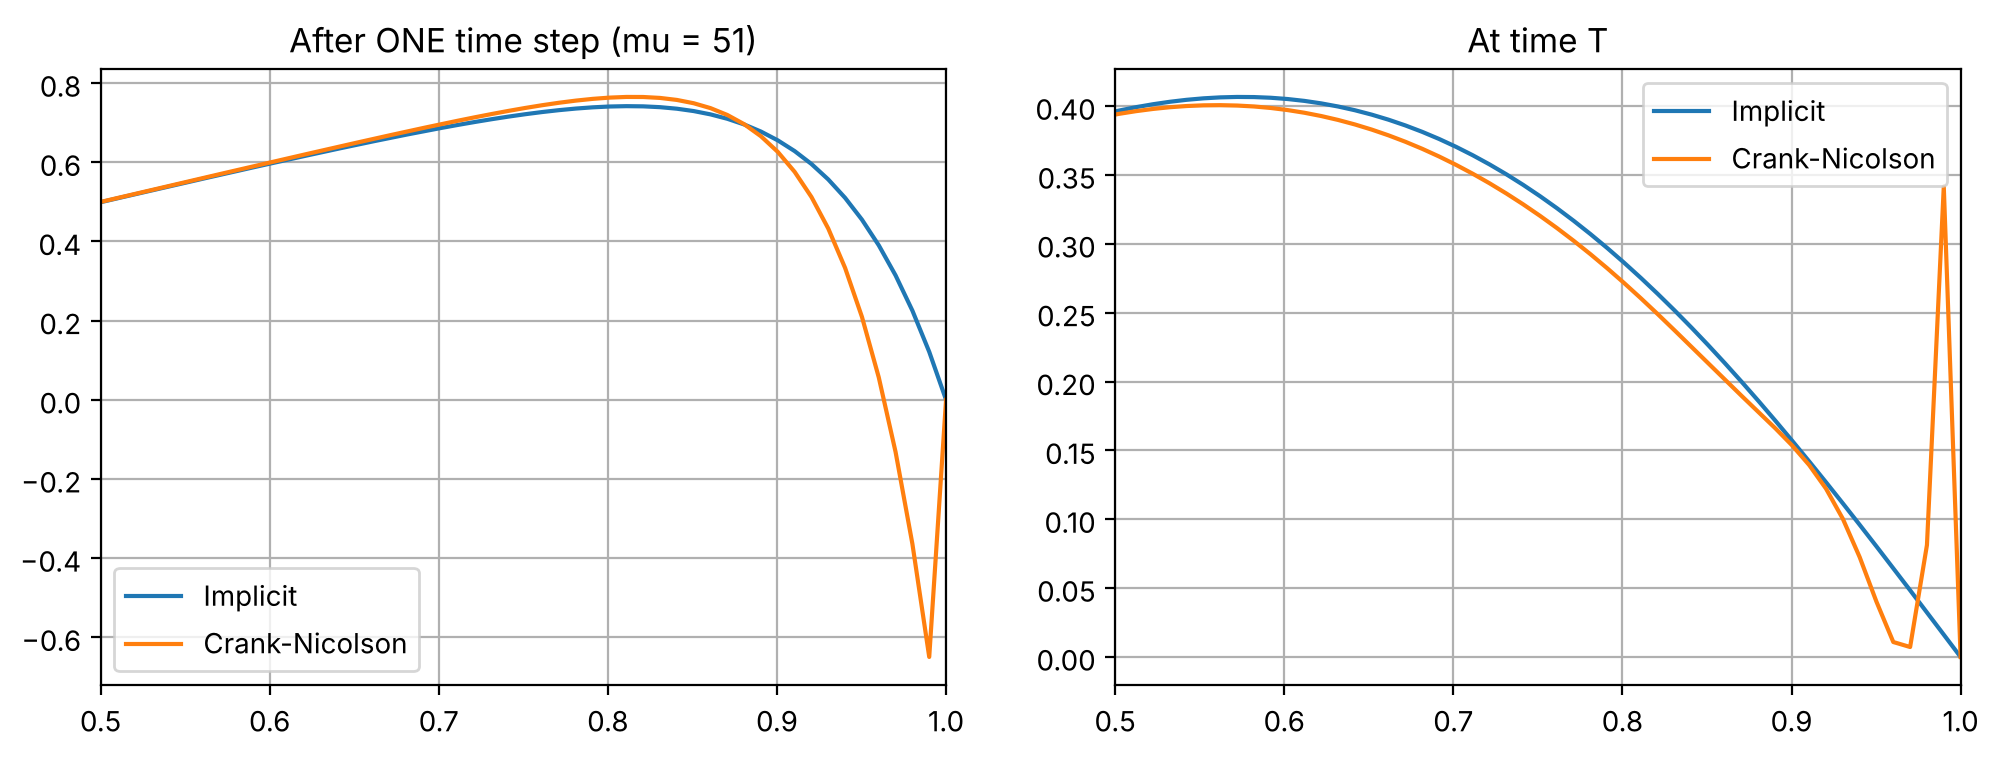

In [ ]:
N, M = 200, 10  
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for theta in [IMPLICIT, CN]:
    x, U, mu = solve(theta, N, M, phi, history=True)
    ax[0].plot(x, U[1], label=NAMES[theta])
    ax[1].plot(x, U[-1], label=NAMES[theta])
ax[0].set_title(f"After ONE time step (mu = {mu:.0f})")
ax[1].set_title("At time T")
for axis in ax:
    axis.set_xlim(0.5, 1); axis.legend()
plt.show()

Near the barrier, Crank-Nicolson produces a **spurious oscillating spike**, while the implicit scheme stays smooth. This is a real issue for barrier options: the delta and gamma are computed precisely near the barrier, and they become very noisy. In practice, one runs a few implicit steps at the start (Rannacher smoothing) before switching to Crank-Nicolson. Keeping $\mu$ moderate also helps.

## 5. Which solver for the linear system?

The matrix $I+\theta\mu A$ is **tridiagonal, symmetric, positive definite and strictly diagonally dominant**. The natural choice is therefore **Gaussian elimination specialized to tridiagonal matrices**, i.e. the **Thomas algorithm**. It performs one forward sweep and one back substitution in $O(N)$ operations, and needs no pivoting thanks to diagonal dominance. `scipy.linalg.solve_banded` does exactly this.

By contrast, a dense solver (`np.linalg.solve`) costs $O(N^3)$ and stores $N^2$ coefficients, while only $3N$ are nonzero. Since the matrix does not change from one step to the next, one could also factorize it once (LU or Cholesky) and only perform the substitutions at each step.

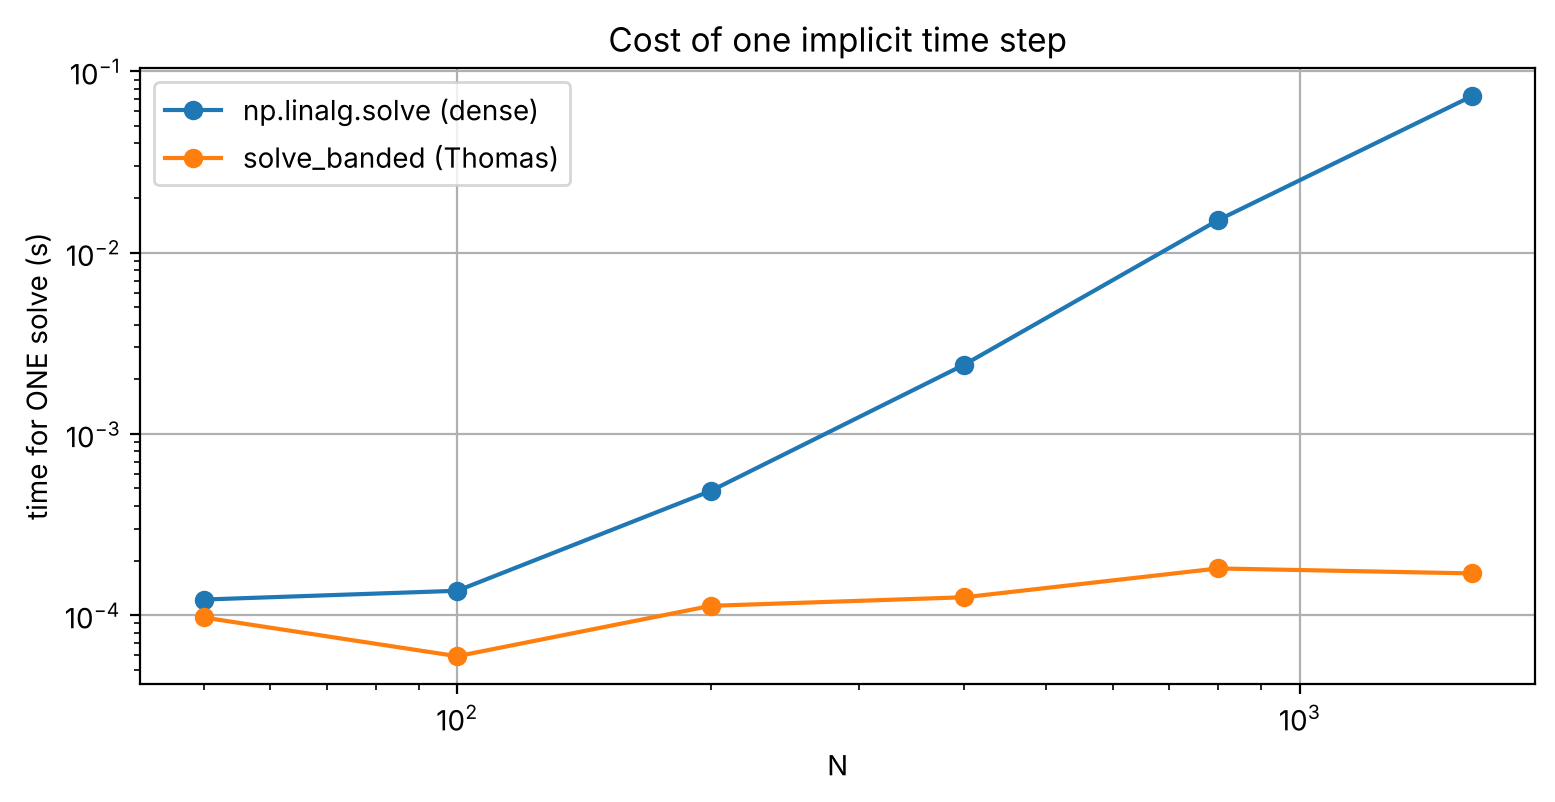

In [8]:
sizes = [50, 100, 200, 400, 800, 1600]
t_dense, t_banded = [], []
for N in sizes:
    mu = 1.0
    A = 2 * np.eye(N) - np.eye(N, k=1) - np.eye(N, k=-1)
    ab = np.zeros((3, N)); ab[0, 1:] = -mu; ab[1, :] = 1 + 2*mu; ab[2, :-1] = -mu
    rhs = np.random.rand(N)
    t0 = time.perf_counter(); np.linalg.solve(np.eye(N) + mu*A, rhs); t_dense.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); sl.solve_banded((1, 1), ab, rhs);        t_banded.append(time.perf_counter() - t0)

plt.loglog(sizes, t_dense, "o-", label="np.linalg.solve (dense)")
plt.loglog(sizes, t_banded, "o-", label="solve_banded (Thomas)")
plt.xlabel("N"); plt.ylabel("time for ONE solve (s)")
plt.title("Cost of one implicit time step")
plt.legend(); plt.show()

## 6. Convergence

We take $\varphi(x)=\sin\!\big(\frac{\pi p(x-a)}{b-a}\big)$, for which the exact solution is known:
$$u_{ex}(x,t)=\exp\!\Big(-t\frac{\sigma^2}{2}\Big(\frac{p\pi}{b-a}\Big)^2\Big)\sin\!\Big(\frac{\pi p(x-a)}{b-a}\Big).$$
This is an eigenmode of the operator: diffusion only **scales its amplitude** by a decaying exponential. The higher the frequency $p$, the faster the decay. We take $p=4$ so that the decay is visible; with $p=1$, $u$ barely moves.

The error is measured as the relative error $\|U-U_{ex}\|/\|U_{ex}\|$ at the points $x_1,\dots,x_N$.

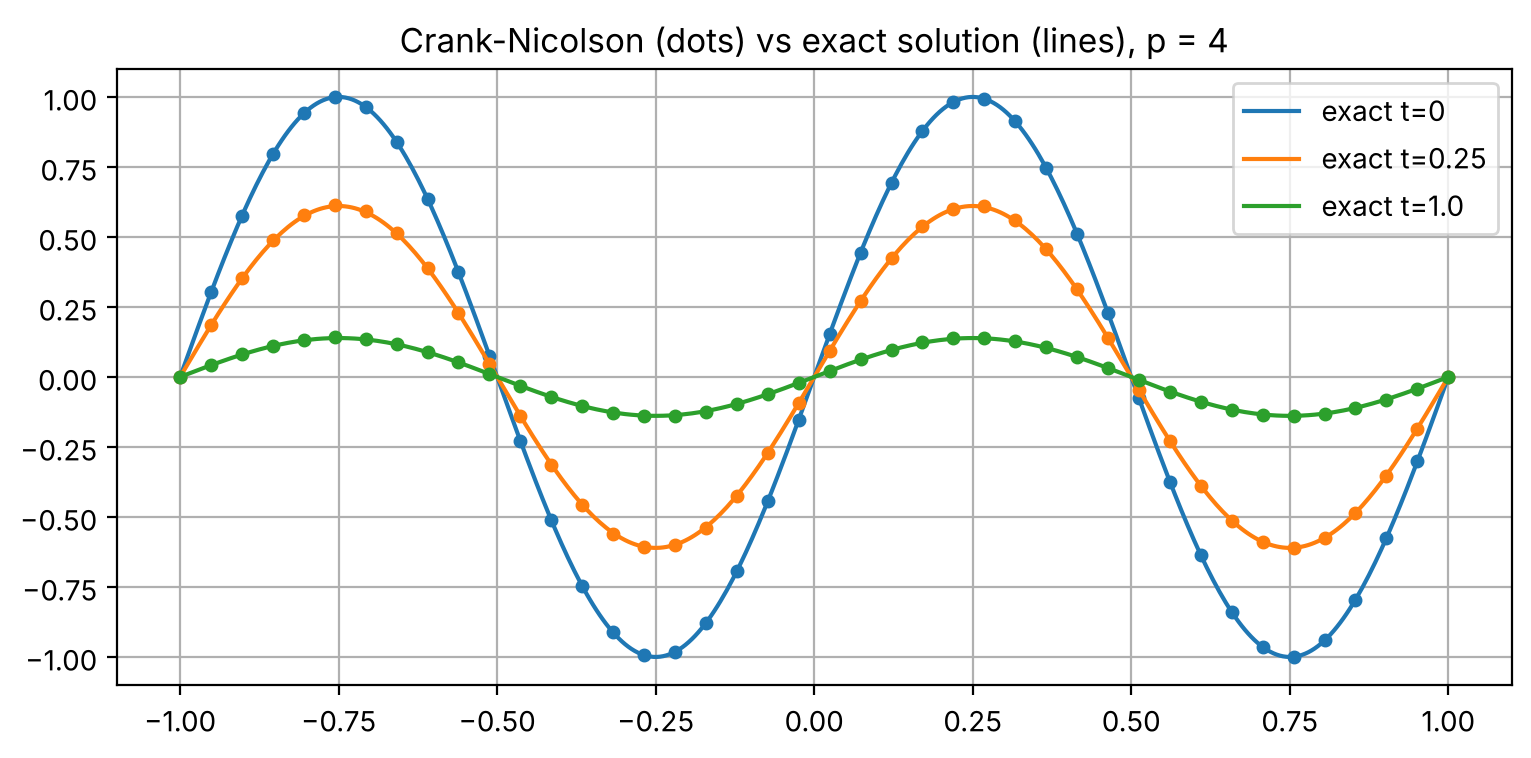

In [ ]:
p = 4

def u_exact(x, t, p=p):
    return np.exp(-t * sigma2 / 2 * (p * np.pi / (b - a))**2) * np.sin(np.pi * p * (x - a) / (b - a))

def rel_error(theta, N, M, p=p):
    x, u, mu = solve(theta, N, M, lambda x: u_exact(x, 0, p))
    ue = u_exact(x[1:-1], T, p)
    return np.linalg.norm(u[1:-1] - ue) / np.linalg.norm(ue)

x, U, mu = solve(CN, 40, 40, lambda x: u_exact(x, 0), history=True)
xf = np.linspace(a, b, 400)
for t in [0, 0.25, 1.0]:
    line, = plt.plot(xf, u_exact(xf, t), label=f"exact t={t}")
    plt.plot(x, U[int(t * 40)], "o", ms=4, color=line.get_color())
plt.title("Crank-Nicolson (dots) vs exact solution (lines), p = 4")
plt.legend(); plt.show()

### 6.1 Observed orders of convergence

- **In space**: fix $M$ very large so that the time error is negligible, and vary $N$.
- **In time**: fix $N$ very large and vary $M$.

On a log-log plot, an error of the form $C h^q$ appears as a straight line of slope $q$.

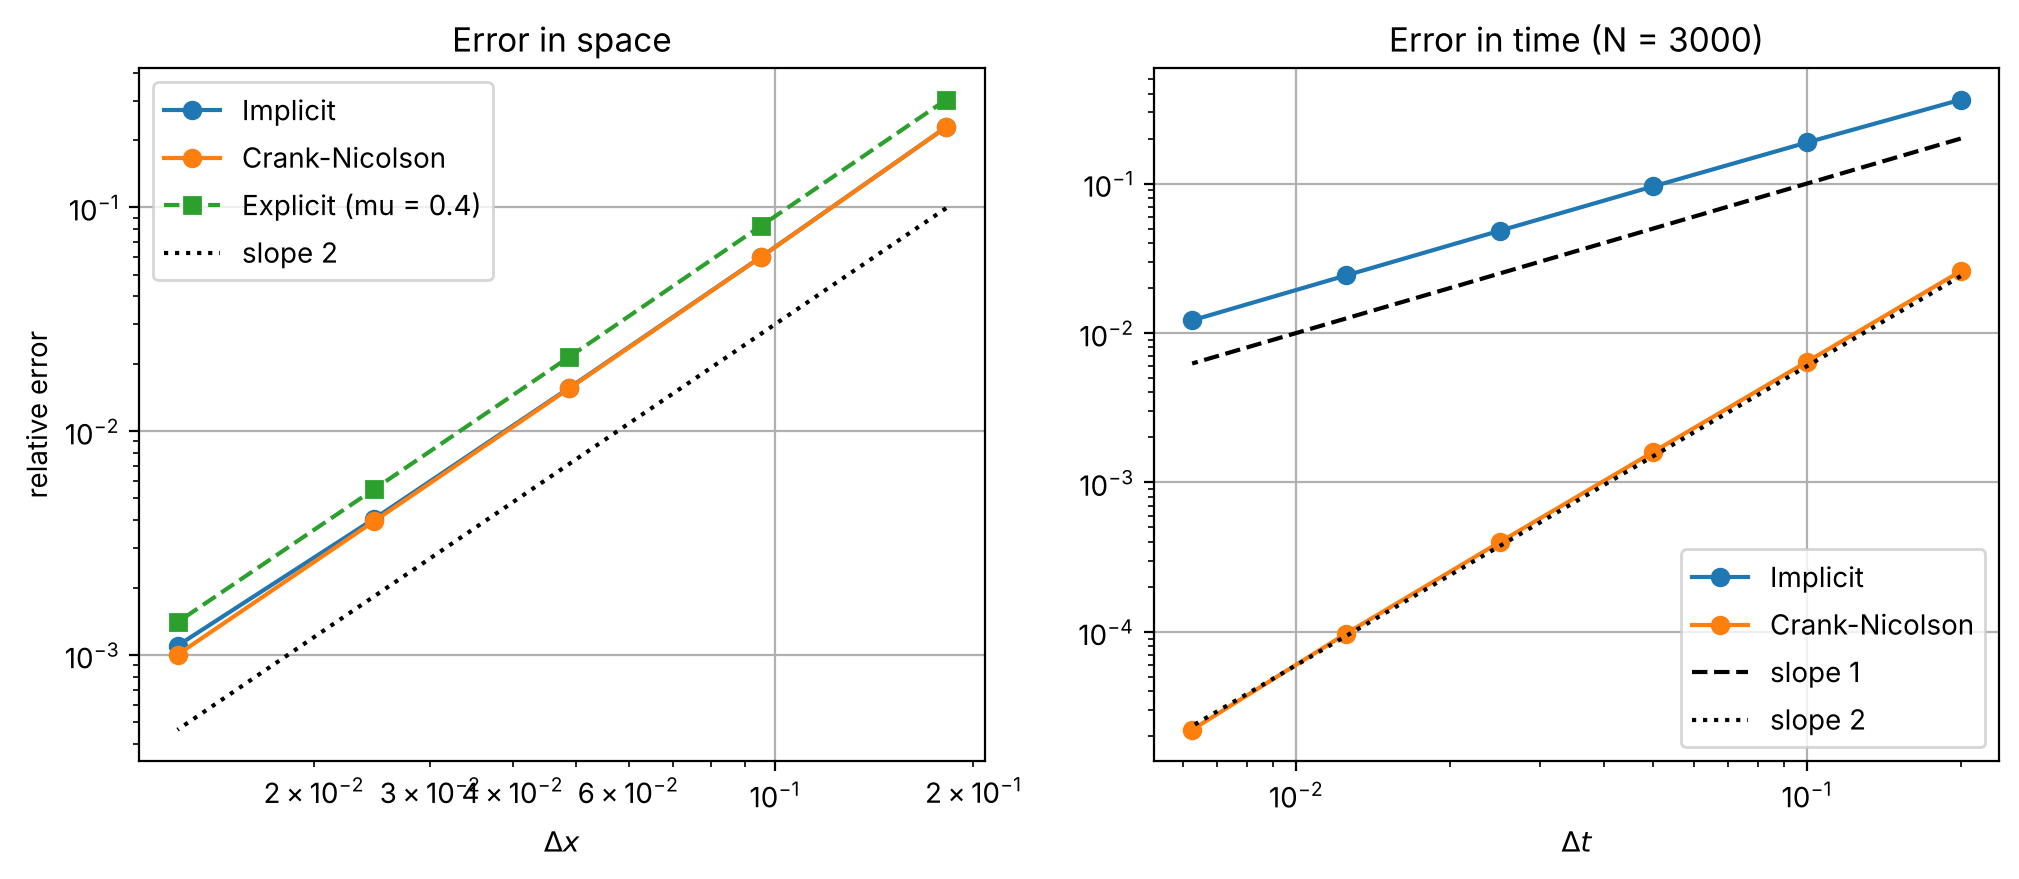

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

N_list = [10, 20, 40, 80, 160]
for theta, M in [(IMPLICIT, 20000), (CN, 2000)]:
    e = [rel_error(theta, N, M) for N in N_list]
    ax[0].loglog([(b-a)/(N+1) for N in N_list], e, "o-", label=NAMES[theta])
# explicit: mu <= 1/2 is required, so M must depend on N
e_exp = []
for N in N_list:
    dx = (b-a)/(N+1)
    M = int(np.ceil(sigma2 * T / (2 * dx**2 * 0.4)))   # mu ≈ 0.4
    e_exp.append(rel_error(EXPLICIT, N, M))
ax[0].loglog([(b-a)/(N+1) for N in N_list], e_exp, "s--", label="Explicit (mu = 0.4)")
h = np.array([(b-a)/(N+1) for N in N_list])
ax[0].loglog(h, 3 * h**2, "k:", label="slope 2")
ax[0].set_xlabel(r"$\Delta x$"); ax[0].set_ylabel("relative error")
ax[0].set_title("Error in space"); ax[0].legend()

M_list = [5, 10, 20, 40, 80, 160]
for theta in [IMPLICIT, CN]:
    e = [rel_error(theta, 3000, M) for M in M_list]
    ax[1].loglog([T/M for M in M_list], e, "o-", label=NAMES[theta])
k = np.array([T/M for M in M_list])
ax[1].loglog(k, 1.0 * k, "k--", label="slope 1")
ax[1].loglog(k, 0.6 * k**2, "k:", label="slope 2")
ax[1].set_xlabel(r"$\Delta t$"); ax[1].set_title("Error in time (N = 3000)"); ax[1].legend()
plt.show()

This matches the theory of Section 4.1:
- in space, all schemes are second order (same discrete Laplacian);
- in time, the implicit scheme is first order and Crank-Nicolson second order. Halving $\Delta t$ halves the error for the implicit scheme, and divides it by 4 for Crank-Nicolson.

There is no "time" curve for the explicit scheme: $\Delta t$ cannot be varied freely with a large $N$, since the condition $\mu\le1/2$ would require a huge $M$.

### 6.2 How to choose $M$ as a function of $N$?

The error behaves like $C_1\Delta x^2 + C_2\Delta t^q$. Refining one direction is pointless if the other one dominates: **the two terms should be balanced**.
- Crank-Nicolson ($q=2$): $\Delta t^2\sim\Delta x^2 \Rightarrow$ **$M\propto N$**.
- Implicit ($q=1$): $\Delta t\sim\Delta x^2 \Rightarrow$ **$M\propto N^2$**.
- Explicit: $\mu\le1/2$ imposes $M\propto N^2$ anyway.

We run a set of tests: let $N$ grow while tying $M$ to $N$ in several ways, and look at the resulting slope.

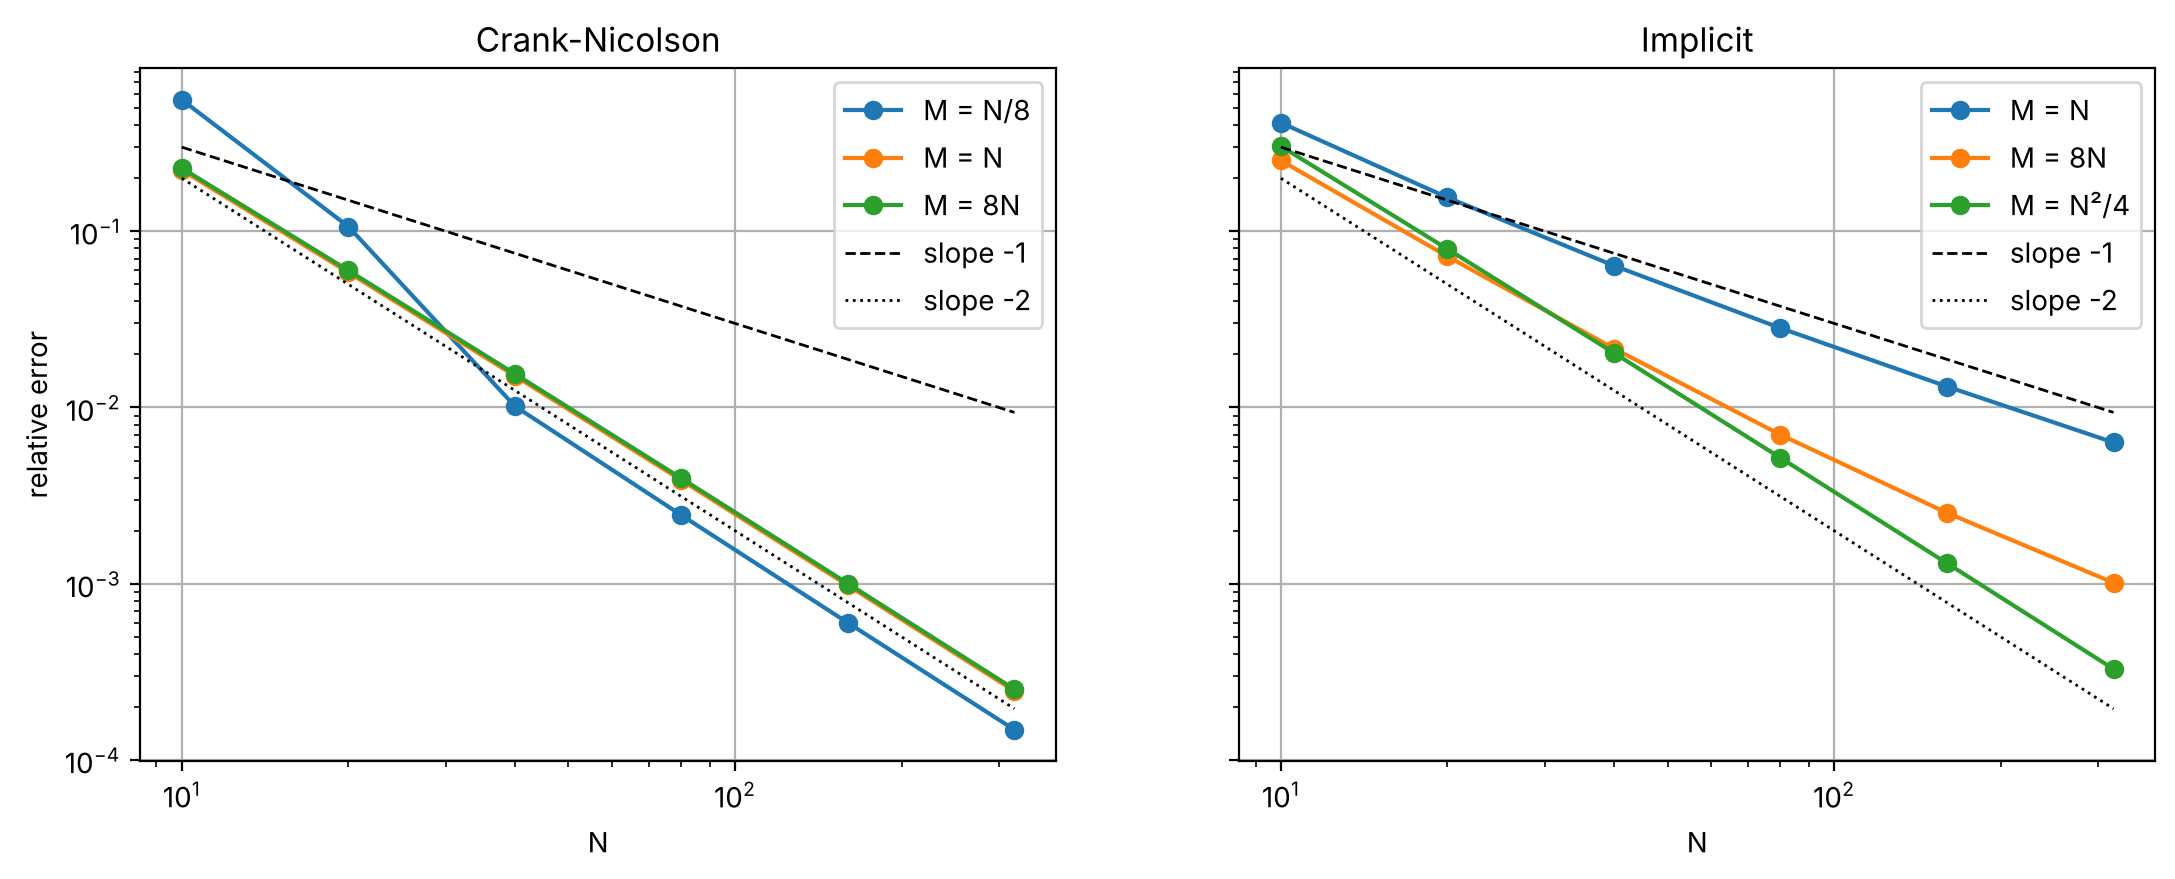

In [11]:
N_list = np.array([10, 20, 40, 80, 160, 320])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

couplings_CN = {"M = N/8": lambda N: max(N // 8, 1), "M = N": lambda N: N, "M = 8N": lambda N: 8 * N}
for label, M_of_N in couplings_CN.items():
    ax[0].loglog(N_list, [rel_error(CN, N, M_of_N(N)) for N in N_list], "o-", label=label)
ax[0].set_title("Crank-Nicolson")

couplings_IMP = {"M = N": lambda N: N, "M = 8N": lambda N: 8 * N, "M = N²/4": lambda N: N * N // 4}
for label, M_of_N in couplings_IMP.items():
    ax[1].loglog(N_list, [rel_error(IMPLICIT, N, M_of_N(N)) for N in N_list], "o-", label=label)
ax[1].set_title("Implicit")

for axis in ax:
    axis.loglog(N_list, 3.0 / N_list, "k--", lw=1, label="slope -1")
    axis.loglog(N_list, 20.0 / N_list**2, "k:", lw=1, label="slope -2")
    axis.set_xlabel("N"); axis.legend()
ax[0].set_ylabel("relative error")
plt.show()

**Reading the plot**
- **Crank-Nicolson**: as soon as $M\propto N$, the error decreases with slope $-2$, whatever the constant. The constant only shifts the error level. With $M=N/8$ the error is even slightly smaller: the time and space errors have opposite signs and partially cancel. This is specific to this test case and should not be relied upon. Taking $M=8N$ brings almost nothing compared to $M=N$, because the error is already dominated by the space component. **$M\approx N$ is enough.**
- **Implicit**: with $M\propto N$, the slope is only $-1$, because the $O(\Delta t)$ time error dominates and the second order in space is wasted. **$M\propto N^2$** is needed to recover slope $-2$.

### 6.3 Which scheme to use? Accuracy vs cost

The cost of a run is proportional to $N\times M$, since the Thomas algorithm costs $O(N)$ per step. We plot the error against the cost, each scheme using its best coupling. At equal cost, the lowest curve wins.

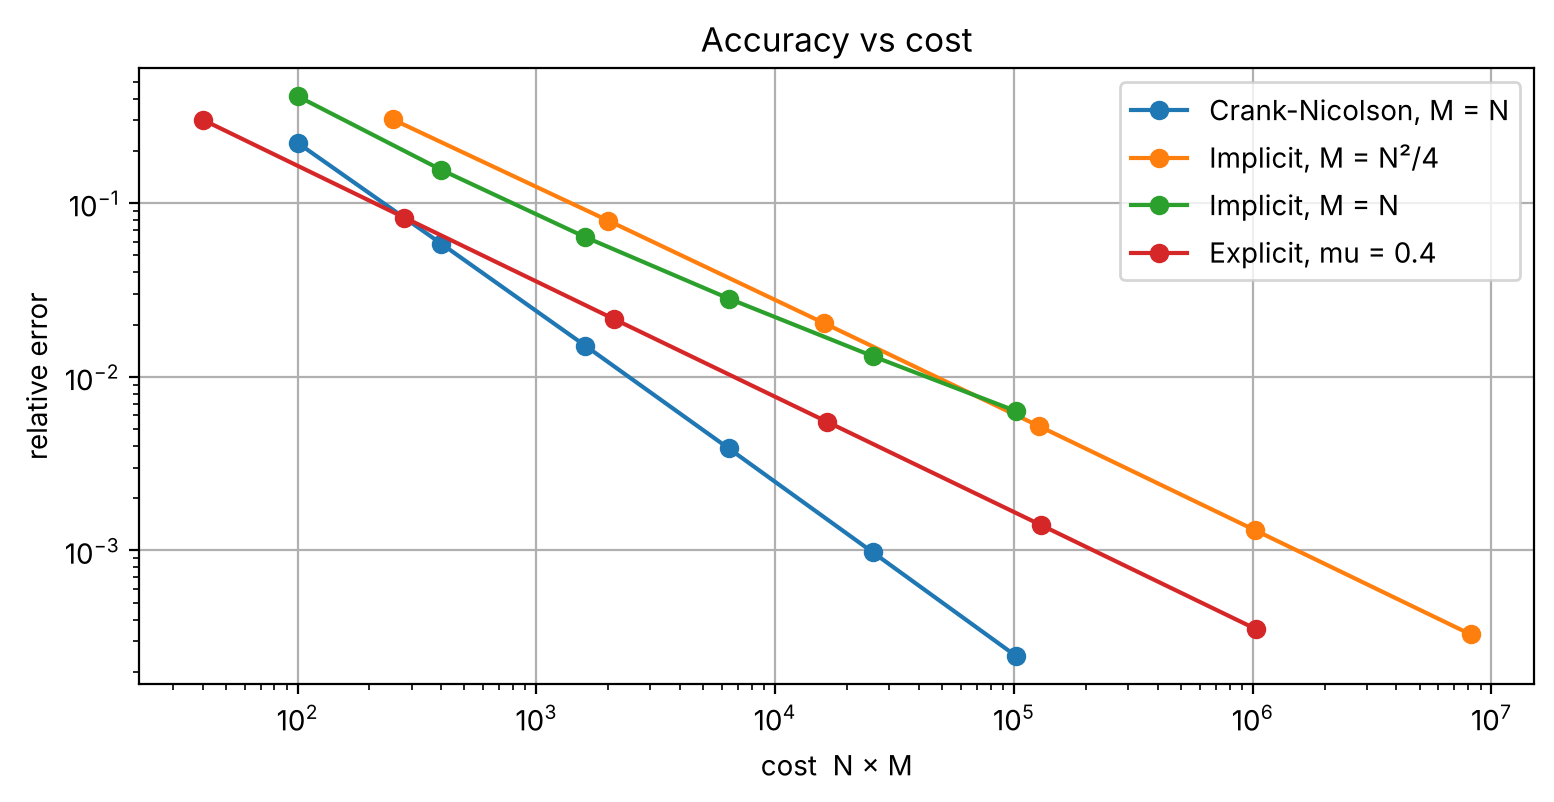

In [12]:
N_list = np.array([10, 20, 40, 80, 160, 320])
settings = [
    (CN,       "Crank-Nicolson, M = N",  lambda N: N),
    (IMPLICIT, "Implicit, M = N²/4",     lambda N: N * N // 4),
    (IMPLICIT, "Implicit, M = N",        lambda N: N),
    (EXPLICIT, "Explicit, mu = 0.4",     lambda N: int(np.ceil(sigma2 * T * (N + 1)**2 / (2 * (b - a)**2 * 0.4)))),
]
for theta, label, M_of_N in settings:
    cost = [N * M_of_N(N) for N in N_list]
    err = [rel_error(theta, N, M_of_N(N)) for N in N_list]
    plt.loglog(cost, err, "o-", label=label)
plt.xlabel("cost  N × M"); plt.ylabel("relative error")
plt.title("Accuracy vs cost")
plt.legend(); plt.show()

**Conclusion: use Crank-Nicolson with $M$ of the order of $N$.**
- Crank-Nicolson: error $\sim N^{-2}$ for a cost $\sim N^2$, so **error $\sim$ cost$^{-1}$**.
- Implicit with $M\propto N^2$, and explicit: error $\sim N^{-2}$ for a cost $\sim N^3$, so error $\sim$ cost$^{-2/3}$.
- Implicit with $M\propto N$: error $\sim N^{-1}$ for a cost $\sim N^2$, so error $\sim$ cost$^{-1/2}$. This is the worst option.

The higher the target accuracy, the larger the advantage of Crank-Nicolson. At low accuracy (error around $10^{-1}$), the explicit scheme remains competitive, since there is no system to solve.

One caveat: with irregular initial data (discontinuous payoff, barrier), it is better to start with a few implicit steps or to keep $\mu$ moderate, to avoid the oscillations of Section 4.3.

## 7. Monte Carlo method

**Idea (Feynman-Kac formula).** The solution of the heat equation can be written as an expectation over the Brownian motion $X_t = x + \sigma W_t$:
- if the path hits a barrier before $T$, it is killed and pays $\alpha$ or $\beta$ (here 0);
- otherwise, it pays $\varphi(X_T)$.

This is **exactly** the definition of a knock-out barrier option: the payoff is averaged over the paths that survived.

**Estimator.** We simulate $K$ discretized paths $X_{m+1}=X_m+\sigma\sqrt{\Delta t}\,\xi_m$ with $\xi_m\sim\mathcal N(0,1)$, then compute $\hat u = \frac1K\sum_k \Phi^{(k)}$, with a 95% confidence interval $\hat u \pm 1.96\,\hat s/\sqrt K$ (central limit theorem).

### 7.1 What the paths look like

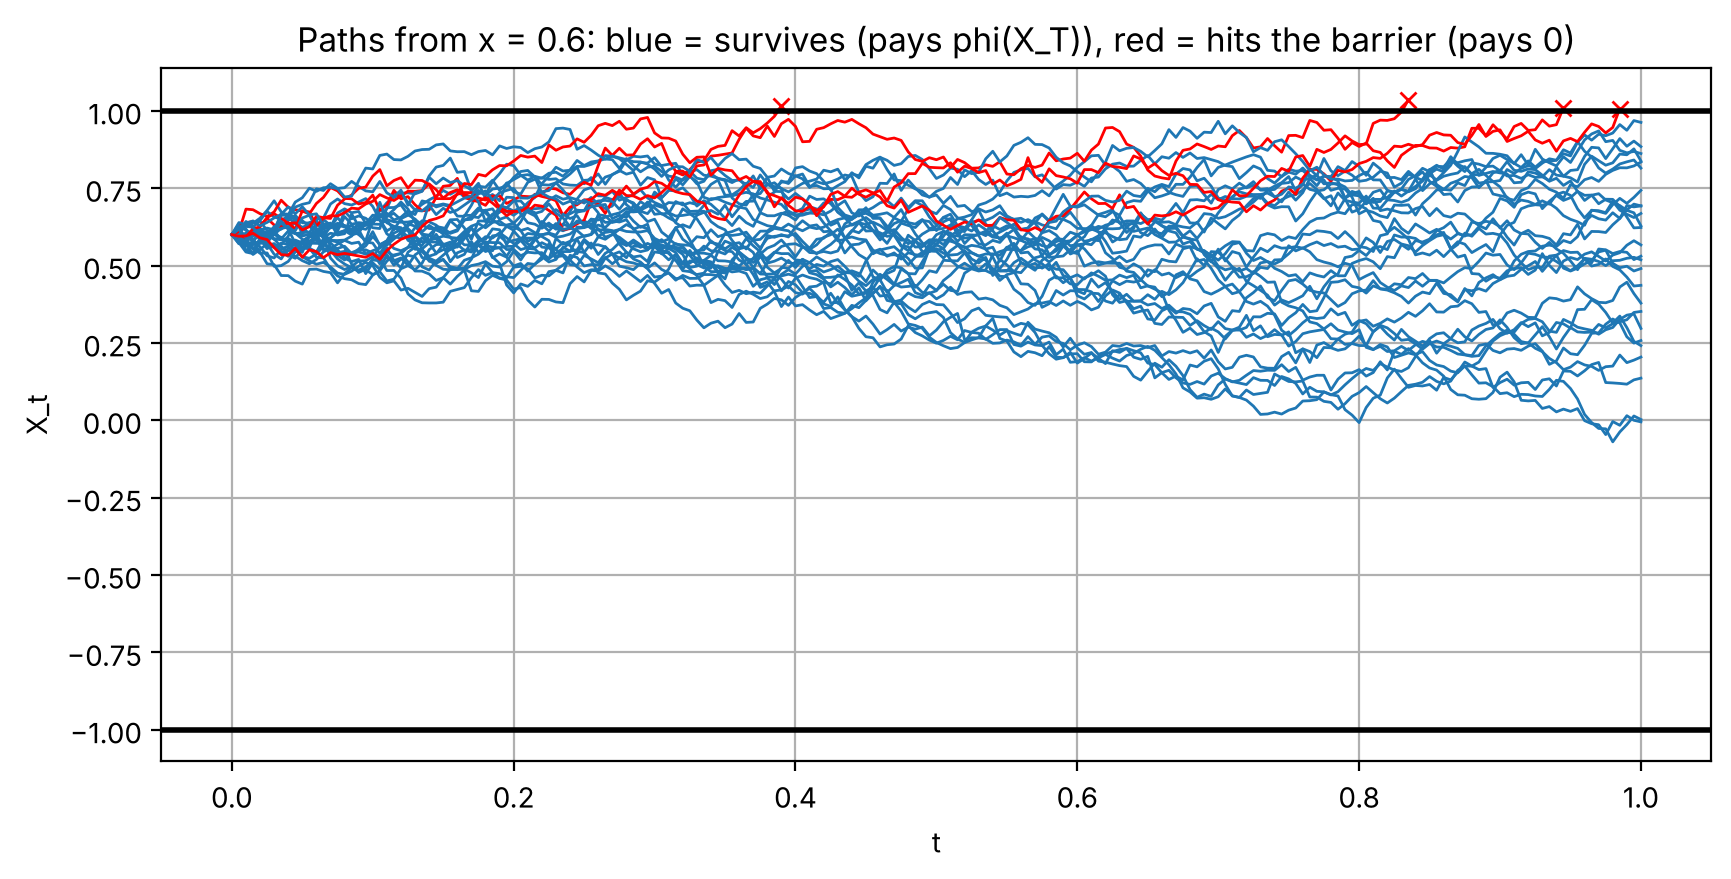

In [13]:
rng = np.random.default_rng(0)
sigma = np.sqrt(sigma2)
M, n_paths, x0 = 200, 30, 0.6
dt = T / M
t = np.linspace(0, T, M + 1)

plt.figure(figsize=(10, 4.5))
for k in range(n_paths):
    X = x0 + np.concatenate([[0], np.cumsum(sigma * np.sqrt(dt) * rng.standard_normal(M))])
    exit_idx = np.where((X <= a) | (X >= b))[0]
    if len(exit_idx) > 0:
        m = exit_idx[0]
        plt.plot(t[:m+1], X[:m+1], color="red", lw=1)
        plt.plot(t[m], X[m], "rx")
    else:
        plt.plot(t, X, color="tab:blue", lw=1)
plt.axhline(a, color="k", lw=2); plt.axhline(b, color="k", lw=2)
plt.title(f"Paths from x = {x0}: blue = survives (pays phi(X_T)), red = hits the barrier (pays 0)")
plt.xlabel("t"); plt.ylabel("X_t"); plt.show()

In [14]:
def monte_carlo(x0, K, M, phi, a=a, b=b, T=T, sigma2=sigma2, alpha=alpha, beta=beta, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    dt = T / M
    X = np.full(K, x0, dtype=float)
    alive = np.ones(K, dtype=bool)
    payoff = np.zeros(K)
    for m in range(M):
        X = X + np.sqrt(sigma2 * dt) * rng.standard_normal(K)
        exit_a = alive & (X <= a)
        exit_b = alive & (X >= b)
        payoff[exit_a] = alpha
        payoff[exit_b] = beta
        alive = alive & ~exit_a & ~exit_b
    payoff[alive] = phi(X[alive])
    return payoff.mean(), 1.96 * payoff.std() / np.sqrt(K)    # estimate, 95% CI half-width

### 7.2 Monte Carlo vs finite differences on the model problem ($\varphi=\max(x,0)$)

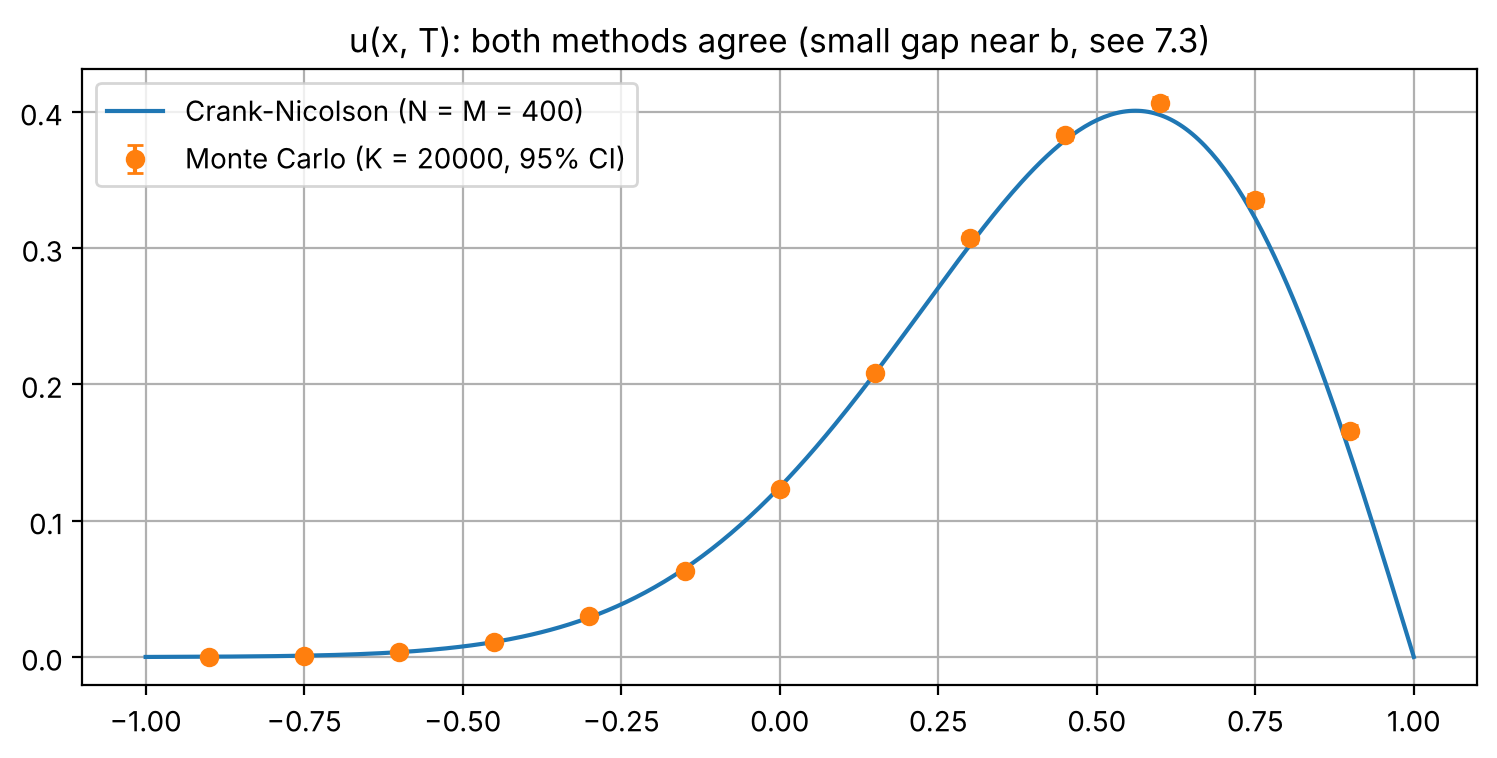

In [15]:
rng = np.random.default_rng(1)
x_fd, u_fd, _ = solve(CN, 400, 400, phi)
points = np.linspace(-0.9, 0.9, 13)
res = np.array([monte_carlo(x0, 20000, 400, phi, rng=rng) for x0 in points])

plt.plot(x_fd, u_fd, label="Crank-Nicolson (N = M = 400)")
plt.errorbar(points, res[:, 0], yerr=res[:, 1], fmt="o", capsize=3, label="Monte Carlo (K = 20000, 95% CI)")
plt.title("u(x, T): both methods agree (small gap near b, see 7.3)")
plt.legend(); plt.show()

### 7.3 The two sources of Monte Carlo error

1. **Statistical error**, of order $1/\sqrt K$: gaining one digit of accuracy requires **100 times** more paths.
2. **Discrete barrier bias.** $X$ is only observed at times $t_m$. A path can exit $[a,b]$ and come back **between two time steps** without being detected. Survival is therefore overestimated, and so is $u$. This bias only decreases like $O(\sqrt{\Delta t})$, and it does not vanish as $K$ grows.

The bias is larger when the payoff is large near the barrier. It is therefore clearly visible on the model problem, $\varphi=\max(x,0)$ with $\varphi(b)=1$, starting from $x=0.8$, close to the upper barrier. The reference value is Crank-Nicolson on a very fine grid ($N=M=2000$).

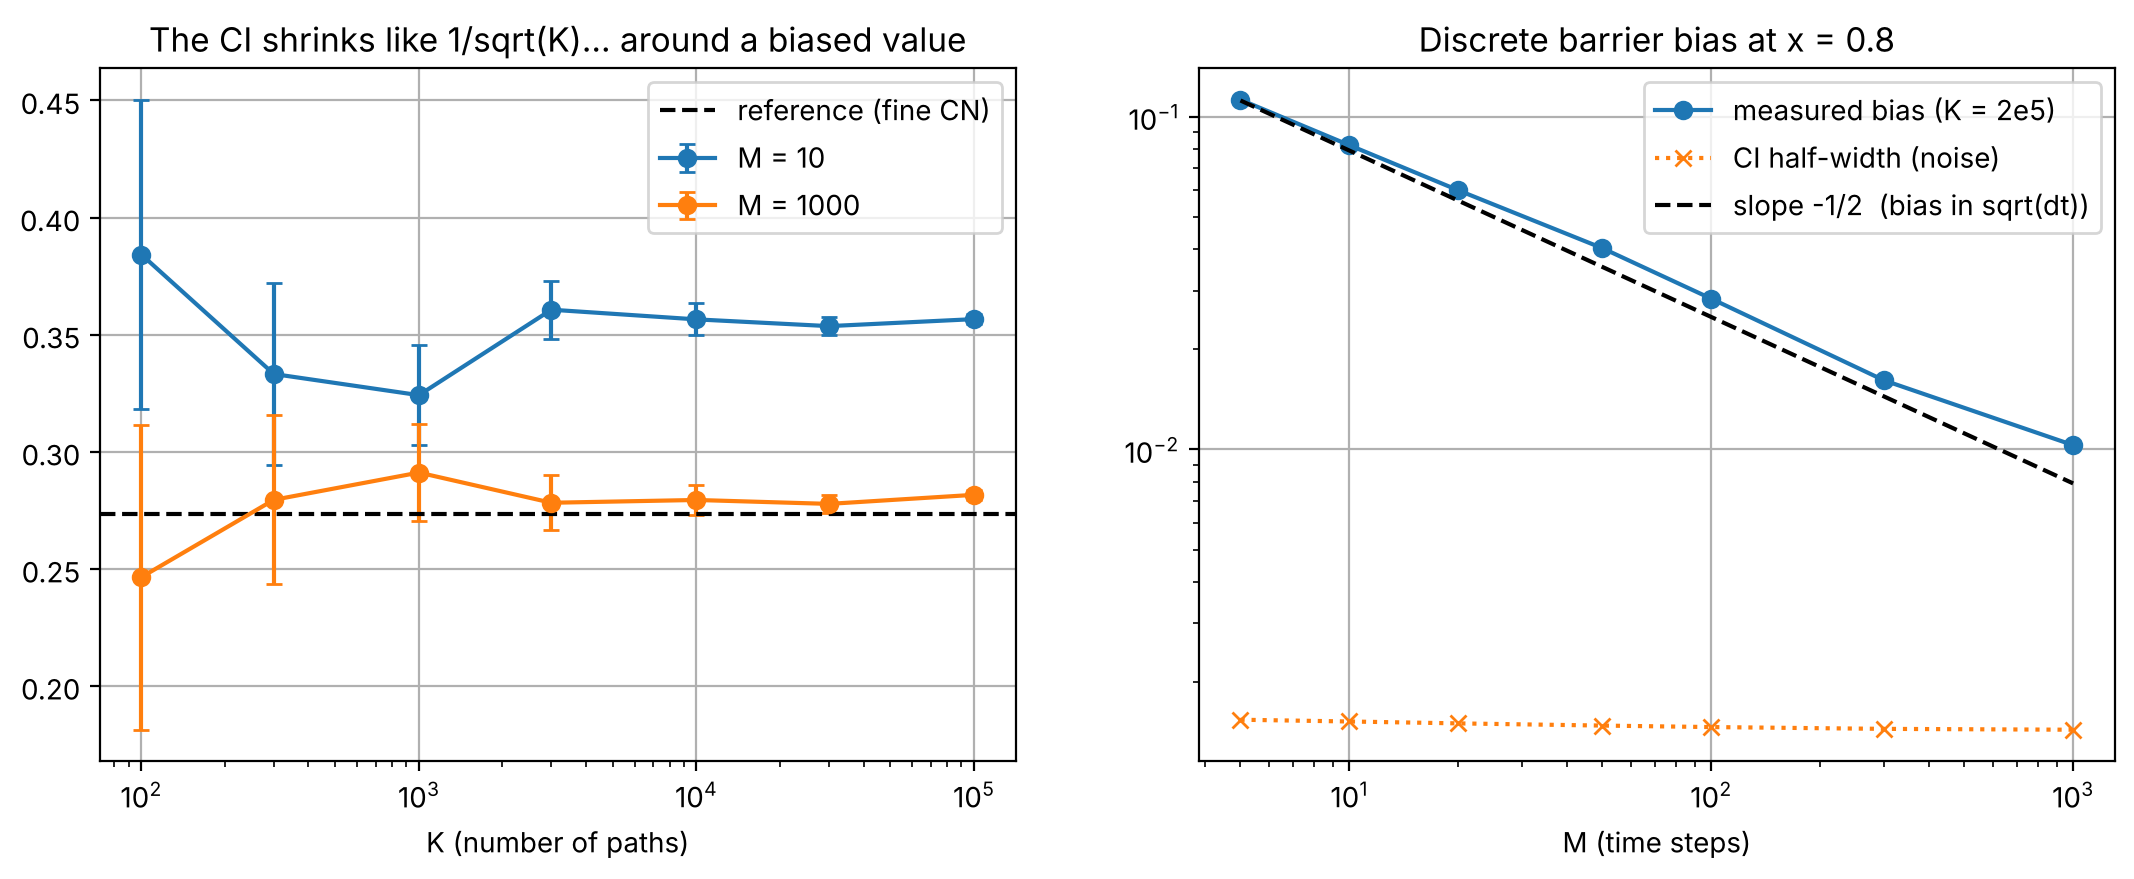

In [16]:
x0 = 0.8
x_ref, u_ref, _ = solve(CN, 2000, 2000, phi)
reference = np.interp(x0, x_ref, u_ref)
rng = np.random.default_rng(2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
K_list = [100, 300, 1000, 3000, 10000, 30000, 100000]
for M in [10, 1000]:
    r = np.array([monte_carlo(x0, K, M, phi, rng=rng) for K in K_list])
    ax[0].errorbar(K_list, r[:, 0], yerr=r[:, 1], fmt="o-", capsize=3, label=f"M = {M}")
ax[0].axhline(reference, color="k", ls="--", label="reference (fine CN)")
ax[0].set_xscale("log"); ax[0].set_xlabel("K (number of paths)")
ax[0].set_title("The CI shrinks like 1/sqrt(K)... around a biased value")
ax[0].legend()

M_list = [5, 10, 20, 50, 100, 300, 1000]
r = np.array([monte_carlo(x0, 200000, M, phi, rng=rng) for M in M_list])
ax[1].loglog(M_list, r[:, 0] - reference, "o-", label="measured bias (K = 2e5)")
ax[1].loglog(M_list, r[:, 1], "x:", label="CI half-width (noise)")
ax[1].loglog(M_list, 0.25 / np.sqrt(M_list), "k--", label="slope -1/2  (bias in sqrt(dt))")
ax[1].set_xlabel("M (time steps)"); ax[1].set_title(f"Discrete barrier bias at x = {x0}")
ax[1].legend()
plt.show()

On the left, with $M=10$, the confidence interval shrinks around a value that is **too high**: this is the bias, and adding paths does not fix it. On the right, the bias is always positive (survival is overestimated) and decreases like $\sqrt{\Delta t}$: multiplying $M$ by 100 only divides it by 10.

In finance, this bias is well known for continuously monitored barrier options. Standard fixes include shifting the barrier (Broadie-Glasserman-Kou correction) or computing the Brownian bridge probability of hitting the barrier between two monitoring dates.

### 7.4 Quantitative accuracy comparison

We go back to the sine case ($p=1$), whose exact solution is known, at $x=0.5$. For Monte Carlo, the accuracy that can be **guaranteed** is the half-width of the confidence interval: the error observed on a single run may be lucky.

In [17]:
p1, x0 = 1, 0.5
phi_sin = lambda x: u_exact(x, 0, p1)
exact = u_exact(x0, T, p1)
rng = np.random.default_rng(3)

print(f"{'Method':<36}{'observed error':>16}{'95% CI (±)':>12}{'time (s)':>11}")
for N in [20, 80, 320]:
    t0 = time.perf_counter()
    x, u, _ = solve(CN, N, N, phi_sin)
    duration = time.perf_counter() - t0
    e = abs(np.interp(x0, x, u) - exact)
    print(f"{f'Crank-Nicolson N = M = {N}':<36}{e:>16.1e}{'-':>12}{duration:>11.4f}")
for K, M in [(1000, 100), (10000, 100), (100000, 1000)]:
    t0 = time.perf_counter()
    est, ci = monte_carlo(x0, K, M, phi_sin, rng=rng)
    duration = time.perf_counter() - t0
    print(f"{f'Monte Carlo K = {K}, M = {M}':<36}{abs(est - exact):>16.1e}{ci:>12.1e}{duration:>11.4f}")

Method                                observed error  95% CI (±)   time (s)
Crank-Nicolson N = M = 20                    1.2e-03           -     0.0005
Crank-Nicolson N = M = 80                    7.9e-05           -     0.0017
Crank-Nicolson N = M = 320                   5.0e-06           -     0.0148
Monte Carlo K = 1000, M = 100                4.3e-03     2.0e-02     0.0018
Monte Carlo K = 10000, M = 100               5.0e-04     6.2e-03     0.0115


Monte Carlo K = 100000, M = 1000             7.7e-05     2.0e-03     1.1565


**Takeaway.** In one dimension, finite differences are far superior. Crank-Nicolson reaches $10^{-5}$ to $10^{-6}$ in a few milliseconds, and gives $u$ **at every grid point** at once. Monte Carlo only guarantees about $10^{-3}$ (the CI width) with $10^5$ paths, in much more time, and for a single $x$. Gaining one more digit would require 100 times more paths.

The strength of Monte Carlo lies elsewhere: its $1/\sqrt K$ rate **does not depend on the dimension**. For an option on 10 underlyings, a finite difference grid would have $N^{10}$ points, which is out of reach, while Monte Carlo remains feasible. It also handles path-dependent payoffs easily.

## 8. Back to Black-Scholes: pricing a double barrier knock-out call

We now apply all of this to an actual option: a call with strike $K=100$, barriers $L=80$ and $U=130$, $\sigma=20\%$, $r=5\%$ and $T=1$ year.

**Change of variables.** Set $x=\ln s$ and $\tau=T-t$. The Black-Scholes equation becomes
$$V_\tau = \tfrac{\sigma^2}{2}V_{xx} + (r-\tfrac{\sigma^2}{2})V_x - rV.$$
Then set $V = e^{cx+d\tau}\,w$ with $c = -\dfrac{r-\sigma^2/2}{\sigma^2}$ and $d = -r-\dfrac{\sigma^2c^2}{2}$. The $V_x$ and $V$ terms vanish, leaving
$$w_\tau = \tfrac{\sigma^2}{2}w_{xx}\quad\text{on } [\ln L,\ln U],\qquad w=0 \text{ at the boundaries},\qquad w(x,0)=e^{-cx}\,(e^x-K)^+ .$$
This is exactly the model problem, so **the same solver** is reused.

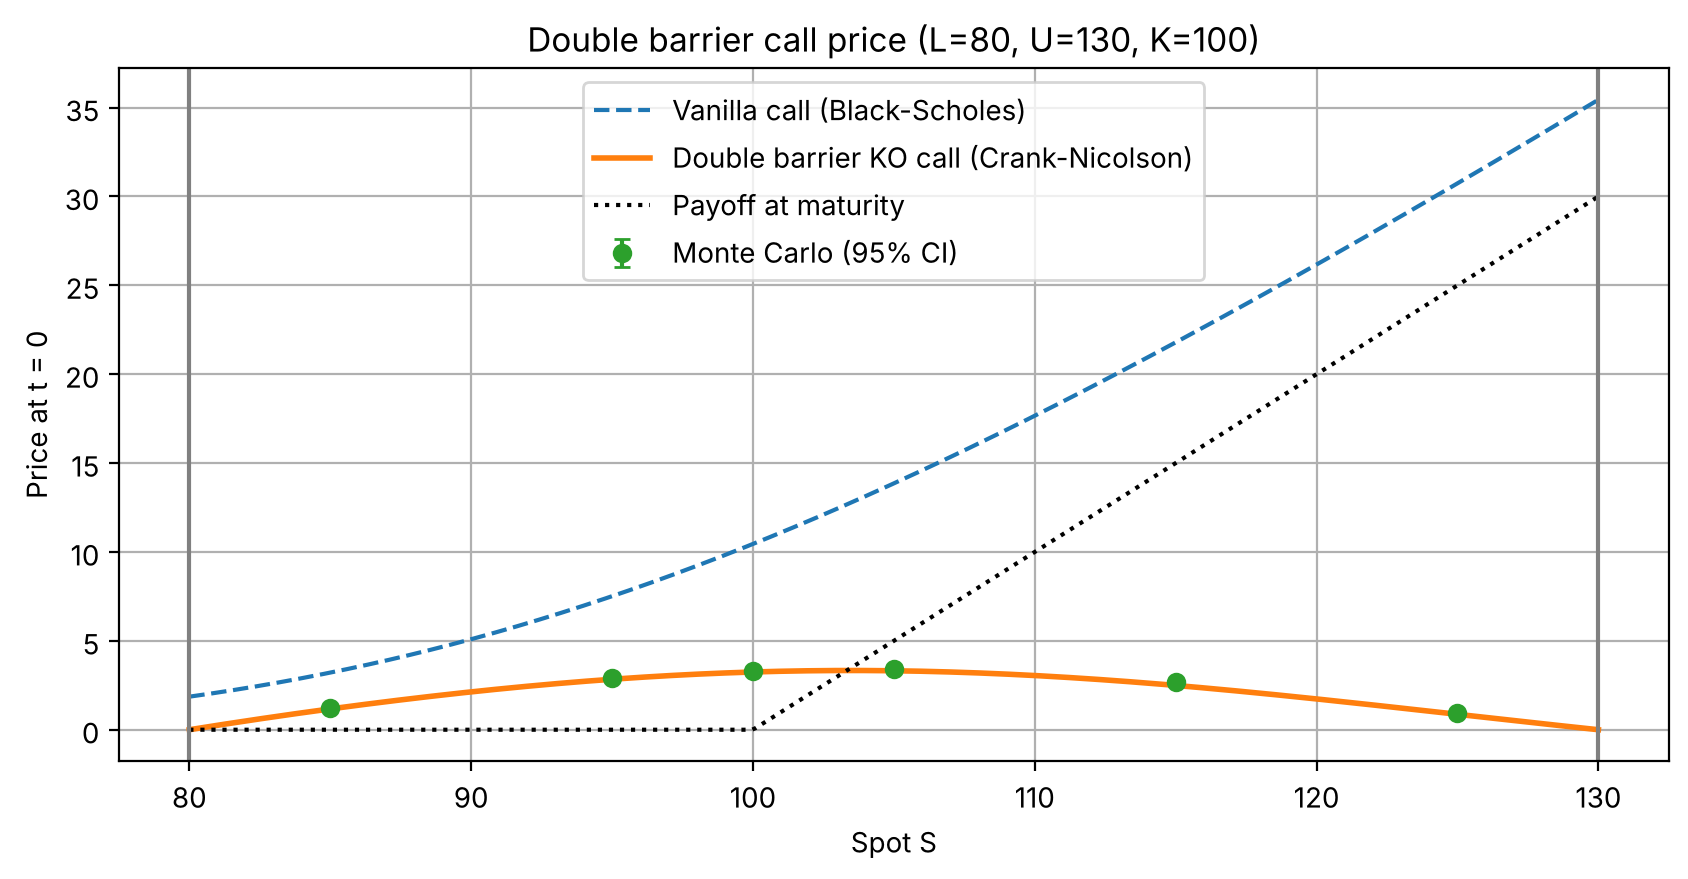

In [18]:
from scipy.stats import norm

K_strike, L, U_bar, vol, r, T_mat = 100.0, 80.0, 130.0, 0.2, 0.05, 1.0
c = -(r - vol**2 / 2) / vol**2
d = -r - vol**2 * c**2 / 2

# 1) Finite differences (Crank-Nicolson) on the heat equation
w0 = lambda x: np.exp(-c * x) * np.maximum(np.exp(x) - K_strike, 0)
xg, w, mu = solve(CN, 400, 400, w0, a=np.log(L), b=np.log(U_bar), T=T_mat, sigma2=vol**2)
S = np.exp(xg)
V_barrier = np.exp(c * xg + d * T_mat) * w

# 2) Vanilla call (Black-Scholes closed form) for comparison
def bs_call(S, K, r, vol, T):
    d1 = (np.log(S / K) + (r + vol**2 / 2) * T) / (vol * np.sqrt(T))
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d1 - vol * np.sqrt(T))

# 3) Monte Carlo under the risk-neutral measure (exact Black-Scholes paths)
def mc_barrier(S0, n_paths=40000, M=1000, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    dt = T_mat / M
    St = np.full(n_paths, S0)
    alive = np.ones(n_paths, dtype=bool)
    for m in range(M):
        St = St * np.exp((r - vol**2 / 2) * dt + vol * np.sqrt(dt) * rng.standard_normal(n_paths))
        alive &= (St > L) & (St < U_bar)
    payoff = np.exp(-r * T_mat) * np.where(alive, np.maximum(St - K_strike, 0), 0.0)
    return payoff.mean(), 1.96 * payoff.std() / np.sqrt(n_paths)

rng = np.random.default_rng(4)
S_mc = np.array([85, 95, 100, 105, 115, 125])
res = np.array([mc_barrier(s0, rng=rng) for s0 in S_mc])

plt.figure(figsize=(10, 4.5))
plt.plot(S, bs_call(S, K_strike, r, vol, T_mat), "--", label="Vanilla call (Black-Scholes)")
plt.plot(S, V_barrier, lw=2, label="Double barrier KO call (Crank-Nicolson)")
plt.errorbar(S_mc, res[:, 0], yerr=res[:, 1], fmt="o", capsize=3, label="Monte Carlo (95% CI)")
plt.plot(S, np.maximum(S - K_strike, 0), "k:", label="Payoff at maturity")
plt.axvline(L, color="grey"); plt.axvline(U_bar, color="grey")
plt.xlabel("Spot S"); plt.ylabel("Price at t = 0")
plt.title(f"Double barrier call price (L={L:.0f}, U={U_bar:.0f}, K={K_strike:.0f})")
plt.legend(); plt.show()

**What the plot shows**
- The barrier call is **much cheaper** than the vanilla call: the holder pays less because everything can be lost if the underlying hits a barrier.
- The price is **zero at the barriers**: these are the Dirichlet conditions $V(L,t)=V(U,t)=0$.
- The price peaks in the middle, then **decreases towards $U$**. The delta therefore becomes **negative** near the upper barrier, whereas a vanilla call always has a positive delta: the higher the spot, the higher the knock-out risk. This is also where gamma is large and where the Crank-Nicolson oscillations of Section 4.3 cause trouble in practice.
- Finite differences and Monte Carlo agree, up to bias. Monte Carlo sits systematically slightly above the Crank-Nicolson curve, because of the discrete barrier bias discussed in 7.3 (barrier only checked at the $M$ monitoring dates). In relative terms the gap is largest near the barriers, where knock-out matters most: about 2% at the money versus about 10% close to $U$.

## 9. Summary of results

| Topic | Result |
|---|---|
| Matrix form | θ-scheme $(I+\theta\mu A)U^{m+1} = (I-(1-\theta)\mu A)U^m + \mu B$, with θ = 0 / 1 / ½ |
| Order of Crank-Nicolson | Taylor expansion centered at $t_{m+1/2}$ ⟹ $\tau = O(\Delta t^2+\Delta x^2)$ (§4.1); confirmed numerically by slopes of 2 (§6.1) |
| Stability of Crank-Nicolson | $g=\frac{1-2\mu s}{1+2\mu s}$, $\lvert g\rvert\le1$ for all $\mu$ ⟹ unconditionally stable; but $g(\pi)\to-1$ ⟹ oscillations for large $\mu$ and irregular data (§4.3) |
| Stability of the explicit scheme | $g=1-4\mu s$ ⟹ stable iff $\mu\le\frac12$, i.e. $\Delta t\le\Delta x^2/\sigma^2$ (parabola, §3.4); beyond that, the zigzag mode blows up (§3.1) |
| Linear solver | Tridiagonal, diagonally dominant matrix ⟹ Thomas algorithm (`solve_banded`), $O(N)$ per step (§5) |
| Convergence | Second order in space for all schemes; first order in time (explicit, implicit), second order (Crank-Nicolson) (§6.1) |
| Best scheme and $M(N)$ | Crank-Nicolson with $M\propto N$; the implicit scheme needs $M\propto N^2$, and the explicit scheme is forced into it by stability (§6.2, §6.3) |
| Monte Carlo | Statistical error in $1/\sqrt K$ + discrete barrier bias in $\sqrt{\Delta t}$; much less accurate than finite differences in 1D, but insensitive to dimension (§7) |